# 2b — Rolling-origin evaluation

Notebook 02 evaluates every model on a single test period (1 to 13 July 2026, about 12 days). This notebook repeats the evaluation on **four consecutive test windows** with an expanding training window (rolling origin), to check whether the comparison with the persistence baselines, the ranking of the models and the value of the day-ahead forecast hold over time.

**Protocol (same as notebook 02, applied to each fold).** Each fold has an inner training period, a 7-day validation period and a test window (fold 4 uses exactly the validation and test periods of notebook 02). The models are fitted on the inner training period and selected on the validation period with the mean CVRMSE criterion. The selected configuration is refitted on the outer training period (inner training plus validation) and evaluated once on the test window. A 12 h embargo separates training from validation and the outer training period from the test window. Feature and target scalers and the operating-regime clustering (k = 8) are refitted for each fold and stage on its own training data only.

**Scope (reduced budget).** The 14 models of notebook 02 are trained with two feature sets, `+ cluster` (no forecast) and `+ day-ahead forecast`, which gives the model comparison and the forecast ablation. The neural networks are tuned with 10 KerasTuner trials and refitted with 3 seeds (20 trials and 5 seeds in notebook 02).

**Caveats.**
* Fold 4 has the same test period as notebook 02, which has already been inspected. It is not a held-out test.
* Fold 1 has only about 2.5 weeks of training data.
* The folds come from the same greenhouse and season, and their training sets overlap, so they are not independent units for a rank test across folds. The inference below uses Diebold–Mariano tests on the test hours of all folds together.

The functions are in `forecast_utils.py`, which reproduces the code of notebook 02 with the split passed as an argument.

In [1]:
import os
import time
import joblib
import numpy as np
import pandas as pd
from IPython.display import display

import forecast_utils as fu
from greenhouse_dataset import TARGET_COLS, get_splits

pd.set_option("display.width", 160)

# ---- run budget -----------------------------------------------------------------------
SMOKE = os.environ.get("GH_SMOKE", "0") == "1"      # quick end-to-end check, numbers NOT meaningful
BUDGET = (fu.Budget(max_trials=1, max_epochs=2, seeds=(0,), rf_trees=10, hgb_iter=20, lookback_grid=(3,))
          if SMOKE else fu.Budget(max_trials=10, seeds=(0, 1, 2)))
RO_FEATURE_SETS = ["+ cluster", "+ day-ahead forecast"]
FS_MAIN, FS_NOFC = "+ day-ahead forecast", "+ cluster"
N_BOOT = 200 if SMOKE else 2000
DM_LAGS = 24
VB_LAGS = (12, 24, 48)

# ---- folds: start of each test window (the last one is the test period of notebook 02) --
SPLITS_02 = get_splits(root=".")
TEST_STARTS = ["2026-06-09 00:00", "2026-06-16 00:00", "2026-06-23 00:00", str(SPLITS_02["test_start"])]
VAL_STARTS = [None, None, None, str(SPLITS_02["val_start"])]   # fold 4 uses exactly the split of notebook 02

# ---- per-fold cache: a fold is retrained only if its file is missing or was made with other settings
RO_DIR = os.path.join("model data", "rolling_origin_smoke" if SMOKE else "rolling_origin")
RO_RERUN = False            # True retrains every fold even if a valid cache file exists
os.makedirs(RO_DIR, exist_ok=True)
print("budget:", BUDGET) 

note: fc_temp_prevday still missing 364h after the short-gap fill; bridging with an unlimited forward-fill of its own past values (flagged in fc_temp_prevday_stale)
note: fc_hum_prevday still missing 364h after the short-gap fill; bridging with an unlimited forward-fill of its own past values (flagged in fc_hum_prevday_stale)
note: fc_viento_prevday still missing 260h after the short-gap fill; bridging with an unlimited forward-fill of its own past values (flagged in fc_viento_prevday_stale)
budget: Budget(max_trials=10, max_epochs=100, patience=8, seeds=(0, 1, 2), rf_trees=200, hgb_iter=300, lookback_grid=(3, 6, 12, 24), kt_dir='kt_tuning_ro')


c:\Users\psyey\OneDrive\Escritorio\Git_repos\Osiris-Greenhouse-UMU\greenhouse_dataset.py:340: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[name] = df[col].shift(-h)


## 2b.1 — Data and folds

In [2]:
D = fu.load_data(root=".")
folds = fu.make_folds(D, TEST_STARTS, VAL_STARTS)
print(f"modelling rows: {len(D['data'])} | common anchor set (24 h complete history): {len(D['anchors'])}")
display(fu.folds_table(folds))

note: fc_temp_prevday still missing 364h after the short-gap fill; bridging with an unlimited forward-fill of its own past values (flagged in fc_temp_prevday_stale)
note: fc_hum_prevday still missing 364h after the short-gap fill; bridging with an unlimited forward-fill of its own past values (flagged in fc_hum_prevday_stale)
note: fc_viento_prevday still missing 260h after the short-gap fill; bridging with an unlimited forward-fill of its own past values (flagged in fc_viento_prevday_stale)
modelling rows: 1456 | common anchor set (24 h complete history): 1374


,inner train end,validation,test,n inner train,n validation,n outer train,n test,test days
fold 1,2026-06-01 00:00:00,2026-06-01 12:00:00 -> 2026-06-08 12:00:00,2026-06-09 00:00:00 -> 2026-06-16 00:00:00,399,128,535,168,7.0
fold 2,2026-06-08 00:00:00,2026-06-08 12:00:00 -> 2026-06-15 12:00:00,2026-06-16 00:00:00 -> 2026-06-23 00:00:00,523,168,703,168,7.0
fold 3,2026-06-15 00:00:00,2026-06-15 12:00:00 -> 2026-06-22 12:00:00,2026-06-23 00:00:00 -> 2026-07-01 07:00:00,691,168,871,199,8.3
fold 4,2026-06-23 02:00:00,2026-06-23 14:00:00 -> 2026-06-30 19:00:00,2026-07-01 07:00:00 -> 2026-07-13 11:00:00,885,173,1070,292,12.2


### 2b.1b — Data overview figure (paper)

One figure that shows the data and the evaluation design together: the training, validation and test periods of the four folds, the interior temperature and relative humidity at the center position (the targets) with the exterior values, the exterior PAR, and the minutes of operation per hour of the 13 climatic systems. Dotted lines mark the start of each test window. Saves `paper/IEEE_Conference_Template/figures/data_overview.pdf`.

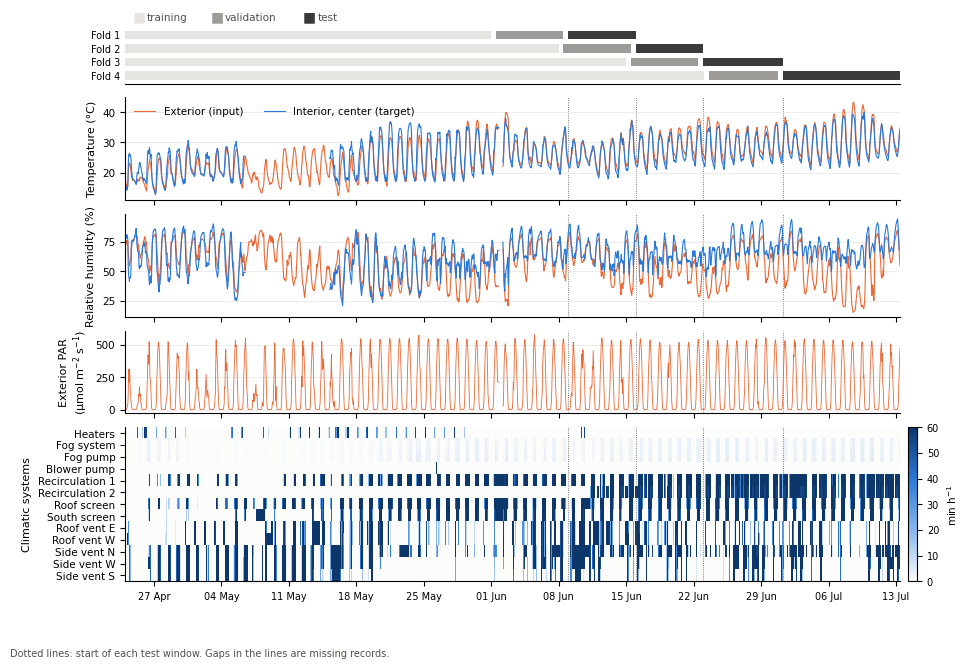

saved: paper\IEEE_Conference_Template\figures\data_overview.pdf


In [3]:
# ---- 2b.1b — Data overview figure for the paper: series, climatic systems and rolling-origin folds ----
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.colors as mcolors

OV_INT, OV_EXT = "#2a78d6", "#eb6834"          # interior (target) / exterior
OV_INK, OV_MUTED = "#0b0b0b", "#52514e"
OV_TRAIN, OV_VAL, OV_TEST = "#e6e5e1", "#9c9b97", "#3a3a38"   # fold timeline: training / validation / test
OV_ACT = {"act_calefactores": "Heaters", "act_fog": "Fog system", "act_bomba_fog": "Fog pump",
          "act_bomba_soplante": "Blower pump", "act_recirculador": "Recirculation 1",
          "act_recirculador2": "Recirculation 2", "act_pantalla_cenital": "Roof screen",
          "act_pantalla_lat_sur": "South screen", "act_vent_cen_este": "Roof vent E",
          "act_vent_cen_oeste": "Roof vent W", "act_vent_lat_norte": "Side vent N",
          "act_vent_lat_oeste": "Side vent W", "act_vent_lat_sur": "Side vent S"}

ov = D["df"].copy()
ov = ov.loc[ov.index <= D["anchors"].max()]
fig, axes = plt.subplots(5, 1, figsize=(10, 7.2), sharex=True,
                         gridspec_kw={"height_ratios": [0.55, 1, 1, 0.8, 1.5], "hspace": 0.14})

# fold timeline: one row per fold with its training, validation and test periods
axf, axes = axes[0], axes[1:]
start = ov.index[0]
for k, f in enumerate(folds, start=1):
    y = len(folds) - k
    for a, b, c in ((start, f.inner_train_end, OV_TRAIN), (f.val_start, f.train_end, OV_VAL), (f.test_start, f.test_end, OV_TEST)):
        axf.barh(y, b - a, left=a, height=0.62, color=c, lw=0)
axf.set_yticks(range(len(folds)))
axf.set_yticklabels([f"Fold {k}" for k in range(len(folds), 0, -1)], fontsize=7)
axf.set_ylim(-0.6, len(folds) - 0.4)
for lab, c, x in (("training", OV_TRAIN, 0.01), ("validation", OV_VAL, 0.11), ("test", OV_TEST, 0.23)):
    axf.text(x, 1.06, "■", color=c, transform=axf.transAxes, fontsize=10, va="bottom")
    axf.text(x + 0.018, 1.08, lab, color=OV_MUTED, transform=axf.transAxes, fontsize=7.5, va="bottom")
for s_ in ("top", "right", "left"):
    axf.spines[s_].set_visible(False)
axf.tick_params(length=0, labelsize=7)
TEST_STARTS_OV = [f.test_start for f in folds]


def shade_folds(ax, labels=False):
    for x in TEST_STARTS_OV:   # start of each test window
        ax.axvline(x, color=OV_MUTED, lw=0.6, ls=":", zorder=0)


panels = ((axes[0], "temp_centro", "ext_temp", "Temperature (°C)"),
          (axes[1], "hum_centro", "ext_hum", "Relative humidity (%)"))
for ax, ci, ce, lab in panels:
    shade_folds(ax, labels=ax is axes[0])
    ax.plot(ov.index, ov[ce], color=OV_EXT, lw=0.8, label="Exterior (input)")
    ax.plot(ov.index, ov[ci], color=OV_INT, lw=0.8, label="Interior, center (target)")
    ax.set_ylabel(lab, fontsize=8)
axes[0].legend(loc="upper left", fontsize=7.5, frameon=False, ncol=2)

shade_folds(axes[2])
axes[2].plot(ov.index, ov["ext_rad_par"], color=OV_EXT, lw=0.6)
axes[2].set_ylabel("Exterior PAR\n(µmol m$^{-2}$ s$^{-1}$)", fontsize=8)

# climatic systems: minutes of operation per hour, one row per system
acts = [c for c in OV_ACT if c in ov.columns]
A = ov[acts].T.values
t0, t1 = mdates.date2num(ov.index[0]), mdates.date2num(ov.index[-1])
cmap = mcolors.LinearSegmentedColormap.from_list("minutes", ["#fcfcfb", "#86b6ef", "#2a78d6", "#0d366b"])
im = axes[3].imshow(A, aspect="auto", cmap=cmap, vmin=0, vmax=60, interpolation="nearest",
                    extent=[t0, t1, len(acts) - 0.5, -0.5])
for x in TEST_STARTS_OV:   # start of each test window
    axes[3].axvline(x, color=OV_MUTED, lw=0.6, ls=":")
axes[3].set_yticks(range(len(acts)))
axes[3].set_yticklabels([OV_ACT[c] for c in acts], fontsize=6.5)
axes[3].set_ylabel("Climatic systems", fontsize=8)
cb = fig.colorbar(im, cax=axes[3].inset_axes([1.01, 0.0, 0.012, 1.0]))   # keeps the shared x scale
cb.set_label("min h$^{-1}$", fontsize=7.5)
cb.ax.tick_params(labelsize=7)

for ax in axes:
    ax.tick_params(labelsize=7.5)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.grid(axis="y", color="#e6e5e1", lw=0.5)
axes[3].grid(False)
axes[3].xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO, interval=1))
axes[3].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
axes[3].set_xlim(ov.index[0], ov.index[-1])
plt.setp(axes[3].get_xticklabels(), rotation=0, fontsize=7)
fig.text(0.01, 0.005, "Dotted lines: start of each test window. Gaps in the lines are missing records.",
         fontsize=7, color=OV_MUTED)

OV_FIG = os.path.join("paper", "IEEE_Conference_Template", "figures", "data_overview.pdf")
os.makedirs(os.path.dirname(OV_FIG), exist_ok=True)
fig.savefig(OV_FIG, bbox_inches="tight")
plt.show()
print("saved:", OV_FIG)

## 2b.2 — Training (one cache file per fold)

Each fold trains 14 models × 2 feature sets. A fold whose cache file exists and matches the current settings is loaded instead of retrained, so the run can be interrupted and resumed.

In [4]:
def fold_fingerprint(f):
    return dict(budget=vars(BUDGET), feature_sets=RO_FEATURE_SETS, models=fu.MODEL_ORDER,
                val=(str(f.val_start), str(f.train_end)), test=(str(f.test_start), str(f.test_end)),
                n=(len(f.idx["inner"]), len(f.idx["val"]), len(f.idx["test"])))

RO = {}
for f in folds:
    path = os.path.join(RO_DIR, f"{f.name.replace(' ', '_')}.joblib")
    if not RO_RERUN and os.path.exists(path):
        cached = joblib.load(path)
        if cached["fingerprint"] == fold_fingerprint(f):
            RO[f.name] = cached["res"]
            print(f"[cache] {f.name} loaded from {path}")
            continue
        print(f"[cache] {f.name}: settings changed, retraining")
    t0 = time.time()
    res = fu.FoldRunner(D, f, BUDGET).run(RO_FEATURE_SETS)
    joblib.dump({"fingerprint": fold_fingerprint(f), "res": res}, path, compress=3)
    RO[f.name] = res
    print(f"{f.name} done in {(time.time() - t0) / 60:.1f} min -> {path}")

[cache] fold 1 loaded from model data\rolling_origin\fold_1.joblib
[cache] fold 2 loaded from model data\rolling_origin\fold_2.joblib
[cache] fold 3 loaded from model data\rolling_origin\fold_3.joblib
[cache] fold 4 loaded from model data\rolling_origin\fold_4.joblib


## 2b.3 — Accuracy per fold

For each fold, the reference baseline of each target is the better of persistence and seasonal persistence on that fold's validation period. The relative MAE is the MAE divided by the MAE of the reference on the same test window, averaged over the six targets (1 = reference, lower is better).

In [5]:
FOLDS = [f.name for f in folds]
METHODS = list(fu.BASELINES) + fu.MODEL_ORDER

def fold_errors(res, fs):
    # hourly absolute errors per method on the fold's test window
    y = res["y_test"]
    e = {b: fu.abs_err(res["baselines_test"][b], y) for b in fu.BASELINES}
    e.update({m: fu.abs_err(res["pred"][(m, fs)], y) for m in fu.MODEL_ORDER})
    return e

ERR = {fn: fold_errors(RO[fn], FS_MAIN) for fn in FOLDS}
REF_MAE = {}
for fn in FOLDS:
    rc = RO[fn]["ref_choice"]
    REF_MAE[fn] = pd.Series({c: ERR[fn][rc[c]][c].mean() for c in TARGET_COLS})

print("Reference baseline per fold and target (chosen on each fold's validation period):")
display(pd.DataFrame({fn: RO[fn]["ref_choice"] for fn in FOLDS}))

rel = pd.DataFrame({fn: {m: (ERR[fn][m].mean() / REF_MAE[fn]).mean() for m in METHODS} for fn in FOLDS})
rel["mean over folds"] = rel.mean(axis=1)
print(f"Relative MAE ({FS_MAIN}), mean over the six targets:")
display(rel.loc[METHODS].round(3))

for kind, cols, unit in (("temperature", fu.TEMP_TARGET_COLS, "degC"), ("humidity", fu.HUM_TARGET_COLS, "%RH")):
    t = pd.DataFrame({fn: {m: ERR[fn][m][cols].mean().mean() for m in METHODS} for fn in FOLDS})
    t["mean over folds"] = t.mean(axis=1)
    print(f"Test MAE, {kind} ({unit}), mean over the three horizons:")
    display(t.loc[METHODS].round(3))

Reference baseline per fold and target (chosen on each fold's validation period):


,fold 1,fold 2,fold 3,fold 4
temp_h1,persistence,persistence,persistence,seasonal persistence
hum_h1,persistence,persistence,persistence,persistence
temp_h6,seasonal persistence,seasonal persistence,seasonal persistence,seasonal persistence
hum_h6,seasonal persistence,seasonal persistence,seasonal persistence,seasonal persistence
temp_h12,seasonal persistence,seasonal persistence,seasonal persistence,seasonal persistence
hum_h12,seasonal persistence,seasonal persistence,seasonal persistence,seasonal persistence


Relative MAE (+ day-ahead forecast), mean over the six targets:


,fold 1,fold 2,fold 3,fold 4,mean over folds
persistence,2.430,3.017,3.201,3.142,2.948
seasonal persistence,1.230,1.131,1.153,1.149,1.166
Ridge,1.046,1.204,0.996,0.859,1.026
RandomForest,0.850,1.197,1.228,1.167,1.110
HistGB,0.746,0.805,0.992,0.803,0.836
LSTM (t only),2.315,1.198,1.160,0.933,1.402
GRU (t only),2.573,1.365,1.280,1.064,1.570
Attention (t only),2.396,1.151,1.117,1.128,1.448
MLP (t only),32.264,1.339,1.317,0.847,8.942
Ridge (hist),1.094,1.167,0.956,0.789,1.001


Test MAE, temperature (degC), mean over the three horizons:


,fold 1,fold 2,fold 3,fold 4,mean over folds
persistence,4.461,4.680,4.682,5.319,4.785
seasonal persistence,1.558,1.117,0.978,1.132,1.196
Ridge,1.587,1.361,0.924,0.966,1.209
RandomForest,1.203,1.365,1.078,1.618,1.316
HistGB,1.016,0.882,0.734,1.007,0.910
LSTM (t only),3.574,1.433,0.932,1.231,1.792
GRU (t only),3.895,1.772,1.206,1.480,2.088
Attention (t only),3.199,1.373,1.120,1.556,1.812
MLP (t only),55.213,1.795,1.195,1.012,14.804
Ridge (hist),1.466,1.260,0.948,0.824,1.125


Test MAE, humidity (%RH), mean over the three horizons:


,fold 1,fold 2,fold 3,fold 4,mean over folds
persistence,9.847,8.046,8.836,7.880,8.652
seasonal persistence,5.763,5.035,5.971,5.398,5.542
Ridge,4.740,4.955,5.430,4.012,4.784
RandomForest,3.909,4.874,6.471,3.948,4.801
HistGB,3.648,3.454,6.205,3.220,4.131
LSTM (t only),8.814,4.618,6.776,3.525,5.933
GRU (t only),10.543,4.674,6.363,3.640,6.305
Attention (t only),10.868,4.480,5.300,3.892,6.135
MLP (t only),98.616,4.264,6.755,3.538,28.293
Ridge (hist),5.654,5.020,4.791,3.915,4.845


## 2b.4 — Model selected on validation in each fold

The configuration with the lowest validation mean CVRMSE over all models and both feature sets, as in notebook 02.

In [6]:
sel_rows = {}
for fn in FOLDS:
    vc = pd.Series(RO[fn]["val_crit"])
    k = vc.idxmin()
    sel_rows[fn] = {"model": k[0], "feature set": k[1], "val mean CVRMSE": vc[k],
                    "test relative MAE": (fu.abs_err(RO[fn]["pred"][k], RO[fn]["y_test"]).mean() / REF_MAE[fn]).mean(),
                    "rank on test (of 14 models)": int(rel.loc[fu.MODEL_ORDER, fn].rank().get(k[0], np.nan))
                    if k[1] == FS_MAIN else np.nan}
display(pd.DataFrame(sel_rows).T)

,model,feature set,val mean CVRMSE,test relative MAE,rank on test (of 14 models)
fold 1,Ridge,+ day-ahead forecast,0.07794,1.045905,5
fold 2,HistGB (hist),+ day-ahead forecast,0.057242,0.820636,2
fold 3,HistGB (hist),+ day-ahead forecast,0.057514,0.987862,2
fold 4,Ridge,+ day-ahead forecast,0.059543,0.859029,4


## 2b.5 — Every model against both persistence baselines, test hours of all folds together

The hourly losses of the four test windows are concatenated (about 33 days instead of 12) and compared with Diebold–Mariano tests, as in section 2.17b of notebook 02. For the pooled score, the loss of each hour is the mean over the six targets of the absolute error divided by the reference MAE of that target in that fold. Holm is applied over the 28 tests (14 models × 2 baselines) of each scope, separately for each HAC bandwidth L.

In [7]:
def concat_losses(err_by_fold, target=None):
    parts = []
    for fn in FOLDS:
        e = err_by_fold[fn]
        if target is None:
            parts.append(pd.DataFrame({m: (e[m][TARGET_COLS] / REF_MAE[fn]).mean(axis=1) for m in METHODS}))
        else:
            parts.append(pd.DataFrame({m: e[m][target] for m in METHODS}))
    return pd.concat(parts).sort_index()

vb_ro = {"pooled": fu.vs_baselines(concat_losses(ERR), max(fu.HORIZONS), fu.MODEL_ORDER, lags=VB_LAGS)}
for c in TARGET_COLS:
    vb_ro[c] = fu.vs_baselines(concat_losses(ERR, c), fu.horizon_of(c), fu.MODEL_ORDER, lags=VB_LAGS)
vb_ro_long = pd.concat([t.assign(scope=s) for s, t in vb_ro.items()], ignore_index=True)
os.makedirs(os.path.join("paper", "tables"), exist_ok=True)
vb_ro_long.to_csv(os.path.join("paper", "tables", "rolling_origin_models_vs_persistence.csv"), index=False)

n_hours = len(concat_losses(ERR))
print(f"{n_hours} test hours over {len(FOLDS)} folds. diff = MAE(model) - MAE(baseline), negative = model better.")
for scope in ["pooled"] + TARGET_COLS:
    t = vb_ro[scope]
    view = {}
    for b, tag in zip(fu.BASELINES, ("P", "S")):
        s = t[t.baseline == b].set_index("model")
        view[(tag, "diff")] = s["diff"].round(3)
        view[(tag, "rel %")] = s["rel diff (%)"].round(1)
        view[(tag, "p Holm L=24")] = s["p Holm (L=24)"].round(3)
        view[(tag, "verdict")] = s["verdict"]
    print(f"\n== {scope}")
    display(pd.DataFrame(view).reindex(fu.MODEL_ORDER))

print("\nNumber of models per verdict, by scope and baseline (all folds together):")
display(vb_ro_long.groupby(["scope", "baseline"])["verdict"].value_counts().unstack(fill_value=0)
        .reindex(["pooled"] + TARGET_COLS, level=0))

827 test hours over 4 folds. diff = MAE(model) - MAE(baseline), negative = model better.

== pooled


P                                         S                                    
                      diff  rel % p Holm L=24         verdict   diff  rel % p Holm L=24          verdict
model                                                                                                   
Ridge               -1.986  -66.5       0.000  better (all L) -0.163  -14.0       0.379             n.s.
RandomForest        -1.863  -62.4       0.000  better (all L) -0.040   -3.4       1.000             n.s.
HistGB              -2.149  -72.0       0.000  better (all L) -0.326  -28.0       0.000   better (all L)
LSTM (t only)       -1.664  -55.7       0.000  better (all L)  0.159   13.7       0.960             n.s.
GRU (t only)        -1.503  -50.3       0.000  better (all L)  0.320   27.5       0.347             n.s.
Attention (t only)  -1.599  -53.5       0.000  better (all L)  0.225   19.3       0.594             n.s.
MLP (t only)         4.456  149.2       0.633            n.s.  6.279  539.9       0.253   worse (some L)
Ridge (hist)        -2.019  -67.6       0.000  better (all L) -0.195  -16.8       0.208  better (some L)
RandomForest (hist) -1.860  -62.3       0.000  better (all L) -0.037   -3.2       1.000             n.s.
HistGB (hist)       -2.116  -70.9       0.000  better (all L) -0.293  -25.2       0.003   better (all L)
LSTM                -1.571  -52.6       0.000  better (all L)  0.252   21.7       0.371             n.s.
GRU                 -1.606  -53.8       0.000  better (all L)  0.217   18.7       0.650             n.s.
Attention           -1.534  -51.4       0.000  better (all L)  0.289   24.8       0.371             n.s.
MLP                 -0.492  -16.5       1.000            n.s.  1.331  114.4       0.176   worse (some L)


== temp_h1


P                                           S                                    
                       diff   rel % p Holm L=24         verdict    diff   rel % p Holm L=24         verdict
model                                                                                                      
Ridge                -0.338   -31.4       0.000  better (all L)  -0.440   -37.4       0.000  better (all L)
RandomForest          0.024     2.2       1.000            n.s.  -0.078    -6.6       1.000            n.s.
HistGB               -0.431   -40.0       0.000  better (all L)  -0.533   -45.2       0.000  better (all L)
LSTM (t only)         0.260    24.1       1.000            n.s.   0.158    13.4       1.000            n.s.
GRU (t only)          0.469    43.6       0.167  worse (some L)   0.366    31.1       0.452            n.s.
Attention (t only)    0.389    36.1       0.296  worse (some L)   0.287    24.3       0.712            n.s.
MLP (t only)         12.217  1135.5       0.296  worse (some L)  12.114  1028.4       0.296  worse (some L)
Ridge (hist)         -0.357   -33.2       0.000  better (all L)  -0.459   -39.0       0.000  better (all L)
RandomForest (hist)   0.080     7.4       1.000            n.s.  -0.022    -1.9       1.000            n.s.
HistGB (hist)        -0.345   -32.1       0.000  better (all L)  -0.447   -38.0       0.001  better (all L)
LSTM                  0.533    49.5       0.117  worse (some L)   0.430    36.5       0.362            n.s.
GRU                   0.429    39.9       0.296  worse (some L)   0.327    27.7       0.712            n.s.
Attention             0.351    32.6       0.494            n.s.   0.249    21.1       1.000            n.s.
MLP                   2.831   263.2       0.187  worse (some L)   2.729   231.7       0.200  worse (some L)


== hum_h1


P                                          S                                   
                       diff  rel % p Holm L=24         verdict    diff  rel % p Holm L=24         verdict
model                                                                                                    
Ridge                -0.240   -8.0       1.000            n.s.  -2.822  -50.4       0.000  better (all L)
RandomForest          0.721   23.9       0.103  worse (some L)  -1.860  -33.3       0.003  better (all L)
HistGB               -0.281   -9.3       0.995            n.s.  -2.862  -51.2       0.000  better (all L)
LSTM (t only)         1.508   50.1       0.103  worse (some L)  -1.073  -19.2       1.000            n.s.
GRU (t only)          1.918   63.7       0.009  worse (some L)  -0.664  -11.9       1.000            n.s.
Attention (t only)    1.818   60.3       0.047  worse (some L)  -0.764  -13.7       1.000            n.s.
MLP (t only)         21.031  698.1       0.185  worse (some L)  18.449  329.8       0.382            n.s.
Ridge (hist)         -0.119   -4.0       1.000            n.s.  -2.701  -48.3       0.000  better (all L)
RandomForest (hist)   0.916   30.4       0.013  worse (some L)  -1.666  -29.8       0.012  better (all L)
HistGB (hist)        -0.251   -8.3       1.000            n.s.  -2.833  -50.6       0.000  better (all L)
LSTM                  1.718   57.0       0.000   worse (all L)  -0.864  -15.4       1.000            n.s.
GRU                   1.456   48.3       0.075  worse (some L)  -1.126  -20.1       1.000            n.s.
Attention             2.304   76.5       0.000   worse (all L)  -0.278   -5.0       1.000            n.s.
MLP                   5.097  169.2       0.047  worse (some L)   2.515   45.0       1.000            n.s.

... (6 outputs left out)


== hum_h12


P                                          S                                   
                       diff  rel % p Holm L=24         verdict    diff  rel % p Holm L=24         verdict
model                                                                                                    
Ridge                -6.775  -55.4         0.0  better (all L)  -0.030   -0.6       1.000            n.s.
RandomForest         -6.935  -56.7         0.0  better (all L)  -0.191   -3.5       1.000            n.s.
HistGB               -7.491  -61.3         0.0  better (all L)  -0.747  -13.6       1.000            n.s.
LSTM (t only)        -5.997  -49.0         0.0  better (all L)   0.748   13.6       1.000            n.s.
GRU (t only)         -6.243  -51.1         0.0  better (all L)   0.502    9.2       1.000            n.s.
Attention (t only)   -6.187  -50.6         0.0  better (all L)   0.557   10.2       1.000            n.s.
MLP (t only)         18.120  148.2         1.0            n.s.  24.864  453.5       0.314  worse (some L)
Ridge (hist)         -6.706  -54.8         0.0  better (all L)   0.038    0.7       1.000            n.s.
RandomForest (hist)  -6.919  -56.6         0.0  better (all L)  -0.174   -3.2       1.000            n.s.
HistGB (hist)        -7.465  -61.1         0.0  better (all L)  -0.721  -13.1       1.000            n.s.
LSTM                 -6.245  -51.1         0.0  better (all L)   0.500    9.1       1.000            n.s.
GRU                  -6.489  -53.1         0.0  better (all L)   0.256    4.7       1.000            n.s.
Attention            -5.460  -44.7         0.0  better (all L)   1.285   23.4       1.000            n.s.
MLP                  -5.473  -44.8         0.0  better (all L)   1.271   23.2       0.635            n.s.


Number of models per verdict, by scope and baseline (all folds together):


verdict                        better (all L)  better (some L)  n.s.  worse (all L)  worse (some L)
scope    baseline                                                                                  
pooled   persistence                       12                0     2              0               0
         seasonal persistence               2                1     9              0               2
temp_h1  persistence                        4                0     4              0               6
         seasonal persistence               4                0     8              0               2
hum_h1   persistence                        0                0     4              2               8
         seasonal persistence               6                0     8              0               0
temp_h6  persistence                       12                1     1              0               0
         seasonal persistence               0                0     6              0               8
hum_h6   persistence                       12                0     2              0               0
         seasonal persistence               0                0    14              0               0
temp_h12 persistence                       13                0     1              0               0
         seasonal persistence               0                0     3              6               5
hum_h12  persistence                       13                0     1              0               0
         seasonal persistence               0                0    13              0               1

### 2b.5b — The same comparison fold by fold

Number of models significantly better than each baseline in each fold (DM, L = 24, Holm over the 28 tests of each fold and target). This shows whether a result found on the pooled test hours appears in every fold or comes from one of them.

In [8]:
per_fold = {}
for fn in FOLDS:
    for c in TARGET_COLS:
        t = fu.vs_baselines(pd.DataFrame({m: ERR[fn][m][c] for m in METHODS}), fu.horizon_of(c), fu.MODEL_ORDER, lags=(DM_LAGS,))
        for b in fu.BASELINES:
            s = t[t.baseline == b]
            per_fold[(c, b, fn)] = int(((s[f"p Holm (L={DM_LAGS})"] < 0.05) & (s["diff"] < 0)).sum())
pf = pd.Series(per_fold).unstack()
pf.index.names = ["target", "baseline"]
display(pf[FOLDS])

fold 1  fold 2  fold 3  fold 4
target   baseline                                            
hum_h1   persistence                1       0       0       1
         seasonal persistence       6       2       0       9
hum_h12  persistence               12       4       5      14
         seasonal persistence       2       0       0       0
hum_h6   persistence                7      14      12      14
         seasonal persistence       4       0       0       0
temp_h1  persistence                2       2       7       6
         seasonal persistence       3       0       3       2
temp_h12 persistence               12      14      14      14
         seasonal persistence       0       0       0       0
temp_h6  persistence                8      14      14      14
         seasonal persistence       0       0       0       0

## 2b.6 — Stability of the model ranking across folds

Models are ranked in each fold by their relative MAE (1 = best). Kendall's W measures the agreement of the four rankings (1 = identical rankings, 0 = no agreement), and the Spearman correlations compare each pair of folds.

In [9]:
ranks = rel.loc[fu.MODEL_ORDER, FOLDS].rank()
ranks["mean rank"] = ranks.mean(axis=1)
display(ranks.sort_values("mean rank").round(1))

m_, n_ = len(FOLDS), len(fu.MODEL_ORDER)
R = ranks[FOLDS].sum(axis=1)
W = 12 * ((R - R.mean()) ** 2).sum() / (m_ ** 2 * (n_ ** 3 - n_))
print(f"Kendall's W over {m_} folds and {n_} models: {W:.2f}")
print("Spearman correlation of the rankings between folds:")
display(ranks[FOLDS].corr(method="spearman").round(2))

,fold 1,fold 2,fold 3,fold 4,mean rank
HistGB,1.0,1.0,3.0,2.0,1.8
HistGB (hist),2.0,2.0,2.0,5.0,2.8
Ridge (hist),6.0,4.0,1.0,1.0,3.0
Ridge,5.0,8.0,4.0,4.0,5.2
LSTM (t only),8.0,7.0,7.0,6.0,7.0
Attention (t only),9.0,3.0,6.0,11.0,7.2
RandomForest (hist),4.0,5.0,9.0,14.0,8.0
RandomForest,3.0,6.0,11.0,13.0,8.2
GRU,10.0,10.0,5.0,8.0,8.2
LSTM,7.0,13.0,8.0,12.0,10.0


Kendall's W over 4 folds and 14 models: 0.60
Spearman correlation of the rankings between folds:


,fold 1,fold 2,fold 3,fold 4
fold 1,1.00,0.76,0.65,0.03
fold 2,0.76,1.00,0.71,0.21
fold 3,0.65,0.71,1.00,0.45
fold 4,0.03,0.21,0.45,1.00


## 2b.7 — Value of the day-ahead forecast for every model

For every model, `+ day-ahead forecast` against `+ cluster` (the same inputs without the forecast), on the test hours of all folds together. `rel (%)` is the change in MAE (negative = the forecast helps), with its block-bootstrap interval and the DM test (L = 24, Holm over the six targets of each model).

In [10]:
ERR_NOFC = {fn: fold_errors(RO[fn], FS_NOFC) for fn in FOLDS}

def concat_model(err_by_fold, m):
    return pd.concat([err_by_fold[fn][m] for fn in FOLDS]).sort_index()

fc_rows, fc_tables = {}, {}
for m in fu.MODEL_ORDER:
    t = fu.paired_rows(concat_model(ERR, m), concat_model(ERR_NOFC, m), L=DM_LAGS, n_boot=N_BOOT)
    fc_tables[m] = t
    fc_rows[m] = {c: f"{t.loc[c, 'rel (%)']:+.1f}{'*' if t.loc[c, 'p Holm'] < 0.05 else ''}" for c in TARGET_COLS}
print("Change in MAE (%) when the day-ahead forecast is added; * = significant (DM, Holm over the six targets):")
display(pd.DataFrame(fc_rows).T.reindex(fu.MODEL_ORDER)[TARGET_COLS])

print("Change in MAE (%) per fold, mean over the six targets:")
display(pd.DataFrame({fn: {m: 100 * ((ERR[fn][m].mean() - ERR_NOFC[fn][m].mean()) / ERR_NOFC[fn][m].mean()).mean()
                           for m in fu.MODEL_ORDER} for fn in FOLDS}).round(1))

pd.concat(fc_tables, names=["model", "target"]).to_csv(os.path.join("paper", "tables", "rolling_origin_forecast_ablation.csv"))
print("saved:", os.path.join("paper", "tables", "rolling_origin_forecast_ablation.csv"))

Change in MAE (%) when the day-ahead forecast is added; * = significant (DM, Holm over the six targets):


,temp_h1,hum_h1,temp_h6,hum_h6,temp_h12,hum_h12
Ridge,+8.6,+4.4,-23.8*,-15.2*,-21.1*,-15.7*
RandomForest,+6.0*,+7.7*,-8.7*,-6.1*,-10.4*,-11.6*
HistGB,-1.1,-3.1,-20.2*,-13.0*,-31.7*,-17.3*
LSTM (t only),-1.2,+8.1,-15.7*,-3.9,-9.0*,-2.9
GRU (t only),-12.5,-4.3,+3.2,+5.2,+0.3,-12.1*
Attention (t only),-7.3,+5.6,-7.2*,-8.6,-15.5*,-9.2*
MLP (t only),+29.7,+19.9,+44.2,-47.0,-8.0*,-22.6
Ridge (hist),-13.7*,-12.6*,-32.4*,-15.4*,-23.5*,-15.9*
RandomForest (hist),-2.9,+0.2,-14.9*,-9.1*,-11.7*,-12.0*
HistGB (hist),+4.5,+1.9,-27.4*,-13.2*,-23.7*,-16.4*


Change in MAE (%) per fold, mean over the six targets:


,fold 1,fold 2,fold 3,fold 4
Ridge,-14.3,4.6,-9.8,-17.1
RandomForest,-2.2,-2.3,-4.0,-4.0
HistGB,-7.4,-20.3,-10.4,-15.6
LSTM (t only),2.0,-9.1,2.7,-15.8
GRU (t only),16.5,-10.9,-3.4,-12.5
Attention (t only),5.8,-14.2,-8.5,-13.2
MLP (t only),4.4,2.1,-11.1,-20.3
Ridge (hist),-5.1,-12.2,-15.0,-29.8
RandomForest (hist),-7.3,-6.5,-6.2,-10.6
HistGB (hist),-7.0,-19.8,-13.6,-9.0


saved: paper\tables\rolling_origin_forecast_ablation.csv


## 2b.8 — Pairwise Diebold–Mariano comparison of all methods, all folds together

The CD-style diagram of notebook 02 (section 2.17), computed on the test hours of the four folds together instead of the test window of fold 4 only. It compares the 16 methods (14 models and the two persistence forecasts) with pairwise DM tests (HAC with `DM_LAGS` lags) and the Holm correction over the 120 pairs.

* **Global diagram**: the loss of each hour is the mean over the six targets (both variables at +1, +6 and +12 h) of the absolute error divided by the MAE of the reference forecast for that target and fold. It is not a +12 h result: h = 12 is only the value used in the Harvey–Leybourne–Newbold correction, the longest horizon, which makes the test slightly conservative.
* **Per-target diagrams**: absolute error of each target divided by the reference MAE of that target and fold, with the horizon of the target in the HLN correction.
* **Axis**: MAE relative to the reference (lower is better). A bar joins methods that are consecutive on the axis and of which no pair differs significantly. The absence of a bar does **not** mean a significant difference.
* **Markers P and S**: test of each method against persistence (P) and seasonal persistence (S): filled circle = significantly better, hollow circle = not distinguishable, red triangle = significantly worse.

The figures are saved in `paper/IEEE_Conference_Template/figures/` (`dm_diagram_rolling_all.pdf` and `dm_diagram_rolling_targets.pdf`).


16 methods, 120 pairs, 827 test hours over 4 folds; 44 pairs significantly different (Holm, alpha = 0.05)
Test of every method against the two persistence forecasts (pooled loss; +1 better, -1 worse, 0 not distinguishable):


,P,S,relative MAE
HistGB,1.0,1.0,0.837
HistGB (hist),1.0,1.0,0.870
Ridge (hist),1.0,0.0,0.968
Ridge,1.0,0.0,1.000
RandomForest,1.0,0.0,1.123
RandomForest (hist),1.0,0.0,1.126
seasonal persistence,1.0,NaN,1.163
LSTM (t only),1.0,0.0,1.322
GRU,1.0,0.0,1.380
Attention (t only),1.0,0.0,1.388


Holm-adjusted DM p-values, all pairs (pooled loss):


,HistGB,HistGB (hist),Ridge (hist),Ridge,RandomForest,RandomForest (hist),seasonal persistence,LSTM (t only),GRU,Attention (t only),LSTM,Attention,GRU (t only),MLP,persistence,MLP (t only)
HistGB,NaN,0.592,0.140,0.004,0.000,0.000,0.002,0.006,0.004,0.001,0.000,0.000,0.000,0.151,0.0,0.751
HistGB (hist),0.592,NaN,0.966,0.247,0.000,0.000,0.019,0.022,0.014,0.002,0.000,0.001,0.001,0.183,0.0,0.752
Ridge (hist),0.140,0.966,NaN,0.966,0.614,0.580,0.752,0.065,0.029,0.008,0.000,0.002,0.002,0.232,0.0,0.769
Ridge,0.004,0.247,0.966,NaN,0.837,0.831,1.000,0.247,0.126,0.044,0.001,0.011,0.011,0.297,0.0,0.787
RandomForest,0.000,0.000,0.614,0.837,NaN,1.000,1.000,1.000,1.000,1.000,0.468,0.831,0.741,0.682,0.0,0.831
RandomForest (hist),0.000,0.000,0.580,0.831,1.000,NaN,1.000,1.000,1.000,1.000,0.468,0.831,0.741,0.682,0.0,0.831
seasonal persistence,0.002,0.019,0.752,1.000,1.000,1.000,NaN,1.000,1.000,1.000,0.964,0.964,0.851,0.682,0.0,0.831
LSTM (t only),0.006,0.022,0.065,0.247,1.000,1.000,1.000,NaN,1.000,0.831,0.831,0.000,0.000,0.326,0.0,0.826
GRU,0.004,0.014,0.029,0.126,1.000,1.000,1.000,1.000,NaN,1.000,1.000,0.151,0.004,0.423,0.0,0.831
Attention (t only),0.001,0.002,0.008,0.044,1.000,1.000,1.000,0.831,1.000,NaN,1.000,0.169,0.309,0.519,0.0,0.831


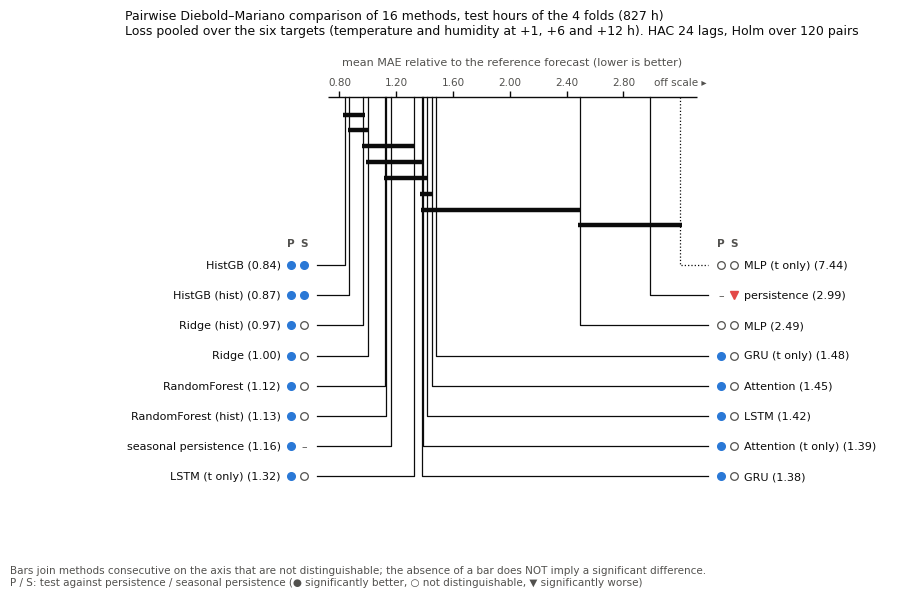

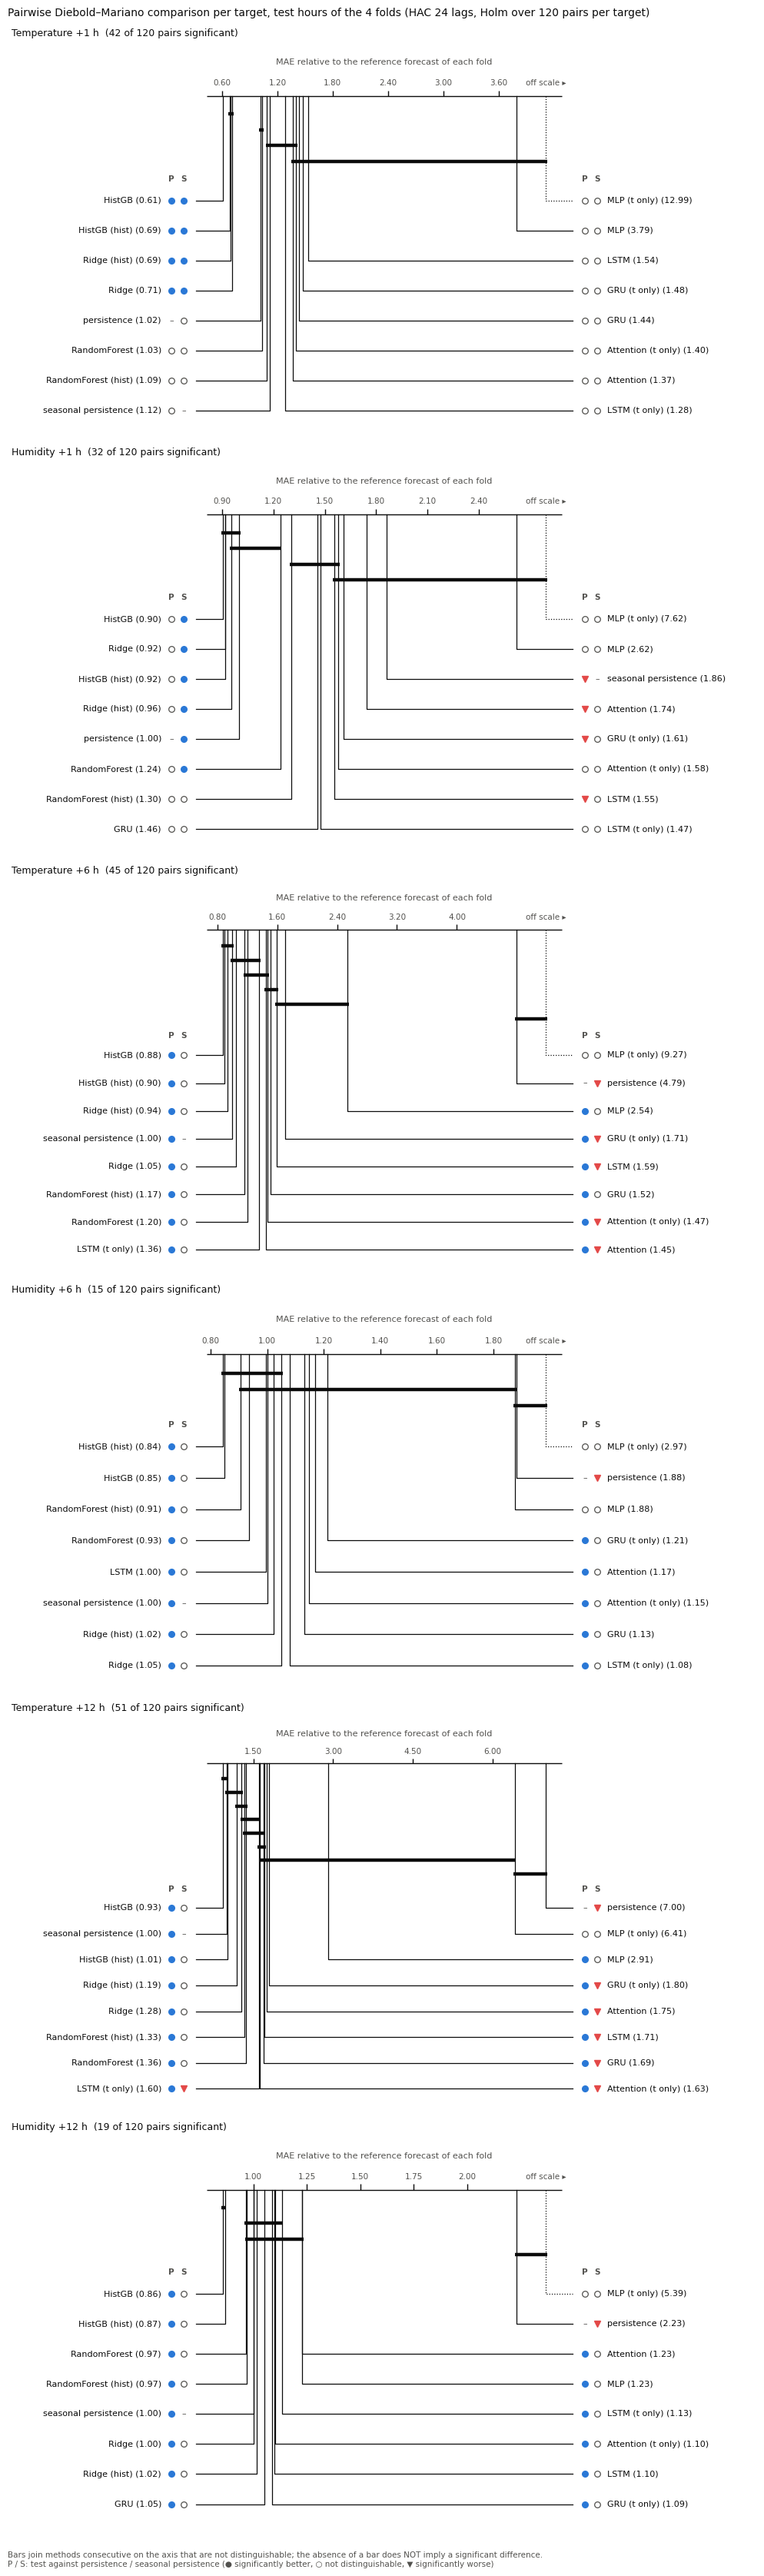

Methods significantly better than each persistence forecast, per target:


,P,S
temp_h1,"Ridge, HistGB, Ridge (hist), HistGB (hist)","Ridge, HistGB, Ridge (hist), HistGB (hist)"
hum_h1,none,"persistence, Ridge, RandomForest, HistGB, Ridg..."
temp_h6,"seasonal persistence, Ridge, RandomForest, His...",none
hum_h6,"seasonal persistence, Ridge, RandomForest, His...",none
temp_h12,"seasonal persistence, Ridge, RandomForest, His...",none
hum_h12,"seasonal persistence, Ridge, RandomForest, His...",none


saved: paper\IEEE_Conference_Template\figures\dm_diagram_rolling_all.pdf and paper\IEEE_Conference_Template\figures\dm_diagram_rolling_targets.pdf


In [11]:
import matplotlib.pyplot as plt

FIG_DIR = os.path.join("paper", "IEEE_Conference_Template", "figures")
os.makedirs(FIG_DIR, exist_ok=True)
TARGET_LABEL = {c: f"{'Temperature' if c.startswith('temp') else 'Humidity'} +{fu.horizon_of(c)} h" for c in TARGET_COLS}

# ---- global diagram: pooled loss over the six targets, test hours of the four folds -------
loss_all_ro = concat_losses(ERR)
pw_all_ro = fu.dm_pairwise(loss_all_ro, h=max(fu.HORIZONS), L=DM_LAGS)
score_all_ro = loss_all_ro.mean()
order_all_ro = list(score_all_ro.sort_values().index)
print(f"{len(METHODS)} methods, {len(pw_all_ro)} pairs, {len(loss_all_ro)} test hours over {len(FOLDS)} folds; "
      f"{int(pw_all_ro['significant'].sum())} pairs significantly different (Holm, alpha = 0.05)")
print("Test of every method against the two persistence forecasts (pooled loss; +1 better, -1 worse, 0 not distinguishable):")
display(pd.DataFrame({tag: fu.baseline_status(pw_all_ro, base) for base, tag in fu.BASELINE_TAGS})
        .reindex(order_all_ro).assign(**{"relative MAE": score_all_ro.round(3)}))
print("Holm-adjusted DM p-values, all pairs (pooled loss):")
display(fu.dm_matrix(pw_all_ro, order_all_ro).round(3))

fig, ax = plt.subplots(figsize=(10, 0.42 * int(np.ceil(len(METHODS) / 2)) + 2.6))
fu.draw_dm_diagram(score_all_ro, pw_all_ro,
                   f"Pairwise Diebold–Mariano comparison of {len(METHODS)} methods, test hours of the {len(FOLDS)} folds "
                   f"({len(loss_all_ro)} h)\nLoss pooled over the six targets (temperature and humidity at +1, +6 and +12 h). "
                   f"HAC {DM_LAGS} lags, Holm over {len(pw_all_ro)} pairs",
                   ax, "mean MAE relative to the reference forecast (lower is better)")
fig.text(0.01, -0.03, fu.DMD_KEY, fontsize=7.5, color=fu.INK2)
fig.savefig(os.path.join(FIG_DIR, "dm_diagram_rolling_all.pdf"), bbox_inches="tight")
plt.show()

# ---- one diagram per target ---------------------------------------------------------------
def concat_rel(target):
    return pd.concat([pd.DataFrame({m: ERR[fn][m][target] / REF_MAE[fn][target] for m in METHODS})
                      for fn in FOLDS]).sort_index()

dmd_ro_target = {}
fig, axes = plt.subplots(len(TARGET_COLS), 1, figsize=(10, len(TARGET_COLS) * (0.42 * int(np.ceil(len(METHODS) / 2)) + 2.3)))
for ax, c in zip(axes, TARGET_COLS):
    loss_c = concat_rel(c)
    pw_c = fu.dm_pairwise(loss_c, h=fu.horizon_of(c), L=DM_LAGS)
    dmd_ro_target[c] = dict(score=loss_c.mean(), pairwise=pw_c)
    fu.draw_dm_diagram(loss_c.mean(), pw_c,
                       f"{TARGET_LABEL[c]}  ({int(pw_c['significant'].sum())} of {len(pw_c)} pairs significant)",
                       ax, "MAE relative to the reference forecast of each fold")
fig.suptitle(f"Pairwise Diebold–Mariano comparison per target, test hours of the {len(FOLDS)} folds "
             f"(HAC {DM_LAGS} lags, Holm over {len(pw_all_ro)} pairs per target)",
             x=0.01, ha="left", fontsize=10, color=fu.INK)
fig.text(0.01, 0.0, fu.DMD_KEY, fontsize=7.5, color=fu.INK2)
plt.tight_layout(rect=(0, 0.01, 1, 0.985))
fig.savefig(os.path.join(FIG_DIR, "dm_diagram_rolling_targets.pdf"), bbox_inches="tight")
plt.show()

print("Methods significantly better than each persistence forecast, per target:")
display(pd.DataFrame({c: {tag: ", ".join(m for m, s in fu.baseline_status(d["pairwise"], base).items() if s == 1) or "none"
                          for base, tag in fu.BASELINE_TAGS} for c, d in dmd_ro_target.items()}).T)
print("saved:", os.path.join(FIG_DIR, "dm_diagram_rolling_all.pdf"), "and", os.path.join(FIG_DIR, "dm_diagram_rolling_targets.pdf"))


## 2b.9 — Contribution of each weather variable

Feature set 5 adds the five day-ahead forecast variables at once. This section tests each variable separately, for the four tabular models (Ridge and HistGB, current hour and history) on the four folds:

* **add one forecast variable to set 4**: the value of that variable on its own;
* **remove one forecast variable from set 5**: the part of its contribution that the other variables cannot replace (weather variables are correlated);
* **add one variable measured by the exterior station at the target hour to set 4**: observed weather, not available in operation. It shows whether a gain is limited by the forecast error or by the variable itself. The station measures PAR while the forecast gives global shortwave radiation, and the station has no precipitation.

Ridge is tuned for each input set as in 2b.2. HistGB keeps the learning rate and lookback selected in 2b.2 for set 4 (additions) or set 5 (removals) in each fold, so the differences come only from the inputs, and the section runs in minutes instead of hours. The neural networks are not included.

Results: one cache file per fold in `model data/rolling_origin/weather_variables/`, and the long table `paper/tables/rolling_origin_weather_variables.csv` (change in MAE, block-bootstrap interval and DM test with Holm over the six targets, on the 827 test hours).

In [12]:
# ---- 2b.9a — Contribution of each weather variable: training (tabular models, four folds) ----
WX_MODELS = ["Ridge", "HistGB", "Ridge (hist)", "HistGB (hist)"]
FC_VARS = {"temperature": "fc_temp_prevday", "humidity": "fc_hum_prevday", "precipitation": "fc_precip_prevday",
           "wind speed": "fc_viento_prevday", "radiation": "fc_rad_prevday"}
OBS_VARS = {"temperature": "ext_temp", "humidity": "ext_hum", "wind speed": "ext_viento", "radiation": "ext_rad_par"}


def target_hour_cols(base):
    # value of a weather variable at each target hour t+h (h = 1, 6, 12)
    return [f"{base}_h{h}" for h in fu.HORIZONS]


SET4, SET5 = D["feature_sets"][FS_NOFC], D["feature_sets"][FS_MAIN]
# name -> (columns, feature set whose selected hyperparameters are reused)
WX_SETS = {"set 4": (SET4, FS_NOFC), "set 5": (SET5, FS_MAIN)}
WX_SETS.update({f"set 4 + {v} (NWP)": (SET4 + target_hour_cols(c), FS_NOFC) for v, c in FC_VARS.items()})
WX_SETS.update({f"set 5 - {v} (NWP)": ([x for x in SET5 if x not in target_hour_cols(c)], FS_MAIN)
                for v, c in FC_VARS.items()})
WX_SETS.update({f"set 4 + {v} (observed)": (SET4 + target_hour_cols(c), FS_NOFC) for v, c in OBS_VARS.items()})
for name, (cols, _) in WX_SETS.items():
    assert all(c in D["data"].columns or c in D["cluster_cols"] for c in cols), name

WX_DIR = os.path.join(RO_DIR, "weather_variables")
os.makedirs(WX_DIR, exist_ok=True)


def wx_fingerprint(f):
    return dict(budget=vars(BUDGET), sets={k: list(v[0]) for k, v in WX_SETS.items()}, models=WX_MODELS,
                val=(str(f.val_start), str(f.train_end)), test=(str(f.test_start), str(f.test_end)))


def pack(df):
    # predictions are stored as plain arrays, so the cache does not depend on the pandas version
    return dict(index=df.index.values, columns=list(df.columns), values=df.to_numpy())


def unpack(p):
    return pd.DataFrame(p["values"], index=pd.DatetimeIndex(p["index"]), columns=p["columns"])


def fit_fixed(runner, arch, cols, params):
    # final stage only, with the hyperparameters (learning rate, lookback) selected in section 2b.2
    ctor, _ = runner.search_space()[arch]
    F = runner.prepare(cols, "final")
    p = {k: v for k, v in params.items() if k != "lookback"}
    model = ctor(p).fit(fu.flat(F["Xtr"], params["lookback"]), F["ytr"])
    return runner.to_frame(F, model.predict(fu.flat(F["Xev"], params["lookback"])))


WX = {}
for f in folds:
    path = os.path.join(WX_DIR, f"{f.name.replace(' ', '_')}.joblib")
    if not RO_RERUN and os.path.exists(path):
        cached = joblib.load(path)
        if cached["fingerprint"] == wx_fingerprint(f):
            WX[f.name] = {k: unpack(v) for k, v in cached["pred"].items()}
            print(f"[cache] {f.name} loaded from {path}")
            continue
        print(f"[cache] {f.name}: settings changed, retraining")
    t0, runner, pred, params = time.time(), fu.FoldRunner(D, f, BUDGET), {}, {}
    for name, (cols, fs_hp) in WX_SETS.items():
        for m in WX_MODELS:
            arch = m.split(" ")[0]
            if arch == "Ridge":
                # Ridge is cheap: full selection of alpha and lookback on the validation period
                out = runner.run_tabular(arch, cols, BUDGET.lookback_grid if m.endswith("(hist)") else (1,))
                p, pr = out["params"], out["test_preds"][0]
            else:
                p = RO[f.name]["params"][(m, fs_hp)]
                pr = fit_fixed(runner, arch, cols, p)
            pred[f"{m}|{name}"], params[f"{m}|{name}"] = pack(pr), p
    joblib.dump({"fingerprint": wx_fingerprint(f), "pred": pred, "params": params}, path, compress=3)
    WX[f.name] = {k: unpack(v) for k, v in pred.items()}
    print(f"{f.name}: {len(pred)} runs in {(time.time() - t0) / 60:.1f} min, saved to {path}")

[cache] fold 1 loaded from model data\rolling_origin\weather_variables\fold_1.joblib
[cache] fold 2 loaded from model data\rolling_origin\weather_variables\fold_2.joblib
[cache] fold 3 loaded from model data\rolling_origin\weather_variables\fold_3.joblib
[cache] fold 4 loaded from model data\rolling_origin\weather_variables\fold_4.joblib


In [13]:
# check: set 4 and set 5, refitted here, against the predictions of section 2b.2. Ridge is reproduced
# exactly; HistGB can differ slightly between scikit-learn versions. All comparisons below use the
# predictions of this section only, so both sides of every comparison come from the same runs.
chk = {}
for fn in FOLDS:
    y = RO[fn]["y_test"]
    for m in WX_MODELS:
        for name, fs in (("set 4", FS_NOFC), ("set 5", FS_MAIN)):
            new_mae = fu.abs_err(WX[fn][f"{m}|{name}"], y).mean()
            old_mae = fu.abs_err(RO[fn]["pred"][(m, fs)], y).mean()
            chk[(fn, m, name)] = 100 * float(((new_mae - old_mae) / old_mae).mean())
print("Difference in MAE with section 2b.2 (%, mean over the six targets):")
display(pd.Series(chk).unstack([1, 2]).round(2))


def wx_err(m, name):
    # hourly absolute error of one model and input set, test hours of the four folds together
    return pd.concat([fu.abs_err(WX[fn][f"{m}|{name}"], RO[fn]["y_test"]) for fn in FOLDS]).sort_index()


WX_COMPARISONS = {  # comparison -> (set A, set B) for each variable; change = MAE(A) / MAE(B) - 1
    "add NWP to set 4": {**{v: (f"set 4 + {v} (NWP)", "set 4") for v in FC_VARS}, "all five (set 5)": ("set 5", "set 4")},
    "remove NWP from set 5": {v: (f"set 5 - {v} (NWP)", "set 5") for v in FC_VARS},
    "add observed to set 4": {v: (f"set 4 + {v} (observed)", "set 4") for v in OBS_VARS},
    # observed weather against the forecast of the same variable: the part of the gain lost to forecast error
    "observed instead of NWP": {v: (f"set 4 + {v} (observed)", f"set 4 + {v} (NWP)") for v in ("temperature", "humidity", "wind speed", "radiation")},
}
wx_rows = []
for comp, pairs in WX_COMPARISONS.items():
    for v, (a, b) in pairs.items():
        for m in WX_MODELS:
            t = fu.paired_rows(wx_err(m, a), wx_err(m, b), L=DM_LAGS, n_boot=N_BOOT)
            for c in TARGET_COLS:
                wx_rows.append({"comparison": comp, "variable": v, "model": m, "target": c,
                                "MAE A": t.loc[c, "MAE A"], "MAE B": t.loc[c, "MAE B"], "rel (%)": t.loc[c, "rel (%)"],
                                "CI 2.5%": t.loc[c, "CI 2.5%"], "CI 97.5%": t.loc[c, "CI 97.5%"],
                                "p DM": t.loc[c, "p DM"], "p Holm": t.loc[c, "p Holm"]})
wx_long = pd.DataFrame(wx_rows)
wx_long.to_csv(os.path.join("paper", "tables", "rolling_origin_weather_variables.csv"), index=False)
print("saved:", os.path.join("paper", "tables", "rolling_origin_weather_variables.csv"))

# compact view: change in MAE (%), * = significant (DM, Holm over the six targets)
wx_long["cell"] = [f"{r:+.1f}{'*' if p < 0.05 else ''}" for r, p in zip(wx_long["rel (%)"], wx_long["p Holm"])]
for comp in WX_COMPARISONS:
    print(f"\nChange in MAE (%) — {comp}; * = significant (DM, {DM_LAGS} lags, Holm over the six targets)")
    s = wx_long[wx_long.comparison == comp]
    display(s.pivot_table(index=["variable", "model"], columns="target", values="cell", aggfunc="first")
            .reindex(columns=TARGET_COLS))

# summary over the four models: mean change (%) and number of models with a significant change
summ = (wx_long.assign(sig=wx_long["p Holm"] < 0.05)
        .groupby(["comparison", "variable", "target"], sort=False)
        .agg(mean_rel=("rel (%)", "mean"), n_sig=("sig", "sum")).reset_index())
summ["cell"] = [f"{r:+.1f} ({n})" for r, n in zip(summ.mean_rel, summ.n_sig)]
print("\nMean change in MAE (%) over the four tabular models (number of models with a significant change):")
display(summ.pivot_table(index=["comparison", "variable"], columns="target", values="cell", aggfunc="first", sort=False)
        .reindex(columns=TARGET_COLS))
summ.to_csv(os.path.join("paper", "tables", "rolling_origin_weather_variables_summary.csv"), index=False)

Difference in MAE with section 2b.2 (%, mean over the six targets):


Ridge       HistGB       Ridge (hist)       HistGB (hist)      
       set 4 set 5  set 4 set 5        set 4 set 5         set 4 set 5
fold 1  -0.0  -0.0  -0.37 -1.35          0.0  -0.0         -0.32 -1.77
fold 2   0.0   0.0  -1.39 -0.89          0.0  -0.0          1.02 -0.39
fold 3   0.0  -0.0   0.99  0.94          0.0   0.0          0.52  0.18
fold 4   0.0  -0.0   0.24 -0.21         -0.0  -0.0         -1.06  0.32

saved: paper\tables\rolling_origin_weather_variables.csv

Change in MAE (%) — add NWP to set 4; * = significant (DM, 24 lags, Holm over the six targets)


target                         temp_h1  hum_h1 temp_h6  hum_h6 temp_h12 hum_h12
variable         model                                                         
all five (set 5) HistGB           -0.0    -4.8  -20.0*  -12.3*   -33.1*  -15.7*
                 HistGB (hist)    +6.4    -1.0  -26.5*  -13.8*   -23.6*  -17.0*
                 Ridge            +8.6    +4.4  -23.8*  -15.2*   -21.1*  -15.7*
                 Ridge (hist)   -13.7*  -12.6*  -32.4*  -15.4*   -23.5*  -15.9*
humidity         HistGB           -0.4    -2.0    -0.0  -14.3*   -10.5*  -18.0*
                 HistGB (hist)    -0.0    -2.6    -5.6  -14.9*     -6.6  -16.2*
                 Ridge          +14.9*    +2.6    +6.5  -11.3*     -4.2  -15.8*
                 Ridge (hist)     -6.5  -14.8*    -4.9  -13.8*     -1.8  -17.3*
precipitation    HistGB           +0.0    +0.0    +0.0    +0.0     +0.0    +0.0
                 HistGB (hist)    +0.0    +0.0    +0.0    +0.0     +0.0    +0.0
                 Ridge          +11.6*    +5.9    +7.2    +1.4     +1.7    +1.7
                 Ridge (hist)     +0.3    -2.5   -4.5*    -2.3     -1.8    -3.4
radiation        HistGB           +1.5   -3.5*    +3.2    +0.1    -5.9*    -2.3
                 HistGB (hist)    -0.2   -3.8*    +0.5    +1.3     -2.1    +0.9
                 Ridge           +10.7    +5.7    -5.9   -3.5*     -3.1    -0.1
                 Ridge (hist)     -1.0    +1.0   -4.7*    -1.3     -2.4    -1.1
temperature      HistGB           -2.2    -1.2  -19.0*    -1.2   -31.0*    -1.6
                 HistGB (hist)    +1.0    -1.2  -27.3*    -2.2   -24.0*    -0.7
                 Ridge            -2.8    -0.8  -29.6*   -5.6*   -22.7*   -3.5*
                 Ridge (hist)   -19.3*  -10.0*  -32.4*    -1.5   -22.5*    +0.3
wind speed       HistGB           +1.5    -1.8    +4.6    -0.1     +1.6    +0.5
                 HistGB (hist)   +3.6*    -4.2    +1.2    +2.1     -0.8    +0.8
                 Ridge            +1.0    +1.0    -0.6    +0.4     -1.9    -1.1
                 Ridge (hist)     +0.3    -3.9   -7.0*    -6.1    -5.2*    -3.5


Change in MAE (%) — remove NWP from set 5; * = significant (DM, 24 lags, Holm over the six targets)


target                      temp_h1 hum_h1 temp_h6  hum_h6 temp_h12 hum_h12
variable      model                                                        
humidity      HistGB           +1.6   -1.4    +2.6   +10.1     +1.6  +15.6*
              HistGB (hist)    +0.8   +0.1    -1.6  +17.9*     +2.3  +20.1*
              Ridge            -0.6   +1.4    -1.9  +10.8*     +1.0  +15.5*
              Ridge (hist)     -1.0   +1.4    -2.1  +10.3*     -1.9  +17.2*
precipitation HistGB           +0.0   +0.0    +0.0    +0.0     +0.0    +0.0
              HistGB (hist)    +0.0   +0.0    +0.0    +0.0     +0.0    +0.0
              Ridge           -7.4*   -4.8    -4.5    -2.5     -5.2    -2.4
              Ridge (hist)   -11.0*   -1.6    -2.9    +3.0     -3.4    +3.4
radiation     HistGB           -1.4   +1.3    -0.6    -2.5     +0.4    -2.7
              HistGB (hist)    -1.1   +0.6    -2.2    -1.9     +2.3    +0.4
              Ridge           -2.4*   -0.6   +2.8*   +2.0*    +1.8*    +0.1
              Ridge (hist)    -5.0*   +5.2    +1.2   +9.8*     +2.7    +6.2
temperature   HistGB           +2.6   +0.5  +25.1*    +1.2   +31.4*    -1.7
              HistGB (hist)    -1.4   +0.4  +28.9*    -1.5   +31.8*    -0.7
              Ridge           +5.2*   -0.1  +24.2*    +0.3   +15.5*    +0.1
              Ridge (hist)    +8.3*   -0.1  +27.9*    +0.1   +18.3*    +0.6
wind speed    HistGB           -1.1   -0.2    +0.4    +0.2     +0.3    -1.5
              HistGB (hist)    -2.2   -0.2    -2.0    -1.3     -1.0    -1.3
              Ridge            -0.8   +0.2    +0.3    +0.8     +1.5    +1.3
              Ridge (hist)     -3.9   +5.9    +1.3   +9.9*     +2.2    +5.5

... (2 outputs left out)


Change in MAE (%) — observed instead of NWP; * = significant (DM, 24 lags, Holm over the six targets)


target                    temp_h1  hum_h1 temp_h6  hum_h6 temp_h12 hum_h12
variable    model                                                         
humidity    HistGB           +2.3   -8.2*    -3.5  -19.9*     +0.2  -21.4*
            HistGB (hist)    -0.4   -7.2*   -7.2*  -18.2*    -9.1*  -19.4*
            Ridge           -9.1*   -6.4*  -10.2*    -7.0    -9.2*    -4.0
            Ridge (hist)     +7.5    +8.6    -6.1    -5.9    -7.6*    -4.3
radiation   HistGB           -0.3    +2.4    -5.7    +0.6     -0.5    +3.2
            HistGB (hist)    -2.3    +0.9   -7.5*    +0.8    +6.5*    -0.2
            Ridge            -0.7    -0.5    +0.7   +5.1*     -1.5    +2.1
            Ridge (hist)     -1.0    +0.7    -2.9   +3.2*     -2.6   +2.3*
temperature HistGB          -7.5*    +1.1  -25.8*   -3.7*   -26.1*    -0.9
            HistGB (hist)  -12.5*   -3.0*  -24.4*    -1.0   -30.1*    -2.4
            Ridge            -5.9    +0.6  -17.1*   +8.2*   -15.2*    +4.8
            Ridge (hist)     -4.5    -0.4  -12.0*    +0.0    -6.9*    -1.7
wind speed  HistGB           +0.6    -0.9    -2.9   -3.5*    -5.1*    -2.6
            HistGB (hist)    -1.8    +1.7    -2.0   -5.2*     -0.3   -4.1*
            Ridge          +11.4*    +3.1    +6.4    -2.3     +3.8    +2.1
            Ridge (hist)    -7.7*  -12.3*    +2.2    -4.4    +9.6*    +1.6


Mean change in MAE (%) over the four tabular models (number of models with a significant change):


target                                      temp_h1    hum_h1    temp_h6     hum_h6   temp_h12    hum_h12
comparison              variable                                                                         
add NWP to set 4        temperature        -5.8 (1)  -3.3 (1)  -27.1 (4)   -2.7 (1)  -25.0 (4)   -1.4 (1)
                        humidity           +2.0 (1)  -4.2 (1)   -1.0 (0)  -13.6 (4)   -5.8 (1)  -16.8 (4)
                        precipitation      +3.0 (1)  +0.8 (0)   +0.7 (1)   -0.2 (0)   -0.0 (0)   -0.4 (0)
                        wind speed         +1.6 (1)  -2.2 (0)   -0.5 (1)   -0.9 (0)   -1.6 (1)   -0.8 (0)
                        radiation          +2.7 (0)  -0.2 (2)   -1.7 (1)   -0.9 (1)   -3.4 (1)   -0.6 (0)
                        all five (set 5)   +0.3 (1)  -3.5 (1)  -25.7 (4)  -14.2 (4)  -25.3 (4)  -16.1 (4)
remove NWP from set 5   temperature        +3.7 (2)  +0.2 (0)  +26.5 (4)   +0.0 (0)  +24.3 (4)   -0.4 (0)
                        humidity           +0.2 (0)  +0.4 (0)   -0.7 (0)  +12.3 (3)   +0.7 (0)  +17.1 (4)
                        precipitation      -4.6 (2)  -1.6 (0)   -1.9 (0)   +0.1 (0)   -2.1 (0)   +0.3 (0)
                        wind speed         -2.0 (0)  +1.4 (0)   -0.0 (0)   +2.4 (1)   +0.7 (0)   +1.0 (0)
                        radiation          -2.5 (2)  +1.6 (0)   +0.3 (1)   +1.8 (2)   +1.8 (1)   +1.0 (0)
add observed to set 4   temperature       -13.1 (4)  -3.7 (2)  -41.8 (4)   -1.9 (1)  -39.5 (4)   -1.5 (0)
                        humidity           +1.6 (0)  -7.7 (2)   -7.8 (2)  -24.5 (4)  -11.9 (2)  -27.0 (4)
                        wind speed         +2.2 (2)  -4.2 (1)   +0.3 (1)   -4.7 (2)   +0.3 (1)   -1.6 (1)
                        radiation          +1.7 (0)  +0.7 (1)   -5.6 (2)   +1.5 (0)   -2.9 (1)   +1.2 (0)
observed instead of NWP temperature        -7.6 (2)  -0.4 (1)  -19.8 (4)   +0.9 (2)  -19.6 (4)   -0.0 (0)
                        humidity           +0.1 (1)  -3.3 (3)   -6.8 (2)  -12.7 (2)   -6.4 (3)  -12.3 (2)
                        wind speed         +0.6 (2)  -2.1 (1)   +0.9 (0)   -3.8 (2)   +2.0 (2)   -0.7 (1)
                        radiation          -1.1 (0)  +0.9 (0)   -3.8 (1)   +2.4 (2)   +0.5 (1)   +1.9 (1)

## 2b.10 — Contribution of each weather variable, neural networks

The same design as 2b.9 (all 16 input variants, the same comparisons and tests) for the 8 neural networks (LSTM, GRU, attention and MLP, current hour and history). Run 2b.2 and 2b.9 first.

* The hyperparameters selected in 2b.2 are reused: those of set 4 for the additions and the oracle, those of set 5 for the removals. Each variant is retrained with the same three seeds, and the error of each hour is averaged over the seeds.
* Set 4 and set 5 are taken from the cache of 2b.2, so 14 variants × 8 networks × 4 folds are trained (448 runs of three seeds each).
* Each finished run is saved at once in `model data/rolling_origin/weather_variables_nn/`, so an interrupted run continues where it stopped. The training time of each run is also saved and summarized, for the discussion of scalability.

Results: `paper/tables/rolling_origin_weather_variables_nn.csv` (long table) and `paper/tables/rolling_origin_weather_variables_nn_summary.csv` (mean over the 8 networks and number of significant changes), shown next to the summary of the tabular models.

In [14]:
# ---- 2b.10a — Contribution of each weather variable, neural networks: training (four folds) ----
# Needs sections 2b.2 (RO: predictions and selected hyperparameters) and 2b.9a (WX_SETS, pack, unpack).
# Same input variants as 2b.9 for the 8 neural models. The hyperparameters selected in 2b.2 for set 4
# (additions) or set 5 (removals) are reused, with the same three seeds. Set 4 and set 5 are taken from
# the cache of 2b.2, so only the other 14 variants are trained. Each finished model is saved at once,
# so an interrupted run continues where it stopped.
NN_MODELS = [m for m in fu.MODEL_ORDER if m.split(" ")[0] in fu.NEURAL_ARCHS]
NN_DIR = os.path.join(RO_DIR, "weather_variables_nn")
os.makedirs(NN_DIR, exist_ok=True)
NN_NEW = [name for name in WX_SETS if name not in ("set 4", "set 5")]


def nn_fingerprint(f):
    return dict(budget=vars(BUDGET), sets={k: list(v[0]) for k, v in WX_SETS.items()}, models=NN_MODELS,
                val=(str(f.val_start), str(f.train_end)), test=(str(f.test_start), str(f.test_end)))


def nn_fit_fixed(runner, arch, cols, params):
    """Final stage only: retrain with the hyperparameters selected in 2b.2, one network per seed."""
    F, L = runner.prepare(cols, "final"), params["lookback"]
    preds = []
    for seed in BUDGET.seeds:
        net = fu.NEURAL_BUILDERS[arch](n_features=F["Xtr"].shape[-1], n_targets=len(TARGET_COLS), lookback=L,
                                       units=params["units"], dropout=params["dropout"], lr=params["lr"],
                                       optimizer=params["optimizer"], seed=seed)
        net.fit(fu.last(F["Xtr"], L), F["ytr"], epochs=params["epochs"], batch_size=32, verbose=0)
        preds.append(runner.to_frame(F, net.predict(fu.last(F["Xev"], L), verbose=0)))
    return preds


NN = {}
NN_TIME = {}
n_total = len(folds) * len(NN_NEW) * len(NN_MODELS)
n_done, t_run = 0, time.time()
for f in folds:
    path = os.path.join(NN_DIR, f"{f.name.replace(' ', '_')}.joblib")
    cache = joblib.load(path) if os.path.exists(path) else None
    if RO_RERUN or cache is None or cache["fingerprint"] != nn_fingerprint(f):
        cache = {"fingerprint": nn_fingerprint(f), "pred": {}, "seconds": {}}
    runner = None
    for name in NN_NEW:
        cols, fs_hp = WX_SETS[name]
        for m in NN_MODELS:
            key = f"{m}|{name}"
            n_done += 1
            if key in cache["pred"]:
                continue
            runner = runner or fu.FoldRunner(D, f, BUDGET)
            t0 = time.time()
            preds = nn_fit_fixed(runner, m.split(" ")[0], cols, RO[f.name]["params"][(m, fs_hp)])
            cache["pred"][key] = [pack(p) for p in preds]
            cache["seconds"][key] = time.time() - t0
            joblib.dump(cache, path, compress=3)
            el = time.time() - t_run
            print(f"{f.name} | {m:>18} | {name:<32} | {cache['seconds'][key]:5.0f} s | "
                  f"{n_done}/{n_total} done, elapsed {el / 3600:.1f} h")
    # set 4 and set 5 come from 2b.2
    NN[f.name] = {k: [unpack(p) for p in v] for k, v in cache["pred"].items()}
    for m in NN_MODELS:
        NN[f.name][f"{m}|set 4"] = fu.as_list(RO[f.name]["pred"][(m, FS_NOFC)])
        NN[f.name][f"{m}|set 5"] = fu.as_list(RO[f.name]["pred"][(m, FS_MAIN)])
    NN_TIME[f.name] = pd.Series(cache["seconds"])
    print(f"[{f.name}] {len(cache['pred'])} variants ready ({path})")

print("Training time per model (seconds for three seeds, mean over variants and folds):")
display(pd.concat(NN_TIME).rename_axis(["fold", "key"]).reset_index()
        .assign(model=lambda d: d["key"].str.split("|").str[0])
        .groupby("model")[0].mean().reindex(NN_MODELS).round(1))

[fold 1] 112 variants ready (model data\rolling_origin\weather_variables_nn\fold_1.joblib)
[fold 2] 112 variants ready (model data\rolling_origin\weather_variables_nn\fold_2.joblib)
[fold 3] 112 variants ready (model data\rolling_origin\weather_variables_nn\fold_3.joblib)
[fold 4] 112 variants ready (model data\rolling_origin\weather_variables_nn\fold_4.joblib)
Training time per model (seconds for three seeds, mean over variants and folds):


model
LSTM (t only)         10.1
GRU (t only)           9.7
Attention (t only)    14.8
MLP (t only)           5.9
LSTM                   9.4
GRU                   11.6
Attention             14.1
MLP                    5.7
Name: 0, dtype: float64

In [15]:
# ---- 2b.10b — Contribution of each weather variable, neural networks: change in MAE on the 827 test hours ----
# Same comparisons and tests as 2b.9b. For each hour, the absolute error is averaged over the three seeds.
def nn_err(m, name):
    return pd.concat([fu.abs_err(NN[fn][f"{m}|{name}"], RO[fn]["y_test"]) for fn in FOLDS]).sort_index()


nn_rows = []
for comp, pairs in WX_COMPARISONS.items():
    for v, (a, b) in pairs.items():
        for m in NN_MODELS:
            t = fu.paired_rows(nn_err(m, a), nn_err(m, b), L=DM_LAGS, n_boot=N_BOOT)
            for c in TARGET_COLS:
                nn_rows.append({"comparison": comp, "variable": v, "model": m, "target": c,
                                "MAE A": t.loc[c, "MAE A"], "MAE B": t.loc[c, "MAE B"], "rel (%)": t.loc[c, "rel (%)"],
                                "CI 2.5%": t.loc[c, "CI 2.5%"], "CI 97.5%": t.loc[c, "CI 97.5%"],
                                "p DM": t.loc[c, "p DM"], "p Holm": t.loc[c, "p Holm"]})
nn_long = pd.DataFrame(nn_rows)
nn_long.to_csv(os.path.join("paper", "tables", "rolling_origin_weather_variables_nn.csv"), index=False)

nn_long["cell"] = [f"{r:+.1f}{'*' if p < 0.05 else ''}" for r, p in zip(nn_long["rel (%)"], nn_long["p Holm"])]
for comp in WX_COMPARISONS:
    print(f"\nChange in MAE (%) — {comp}; * = significant (DM, {DM_LAGS} lags, Holm over the six targets)")
    s = nn_long[nn_long.comparison == comp]
    display(s.pivot_table(index=["variable", "model"], columns="target", values="cell", aggfunc="first")
            .reindex(columns=TARGET_COLS))

# summary over the 8 networks, next to the summary of the 4 tabular models of 2b.9b
nn_summ = (nn_long.assign(sig=nn_long["p Holm"] < 0.05)
           .groupby(["comparison", "variable", "target"], sort=False)
           .agg(mean_rel=("rel (%)", "mean"), n_sig=("sig", "sum")).reset_index())
nn_summ["cell"] = [f"{r:+.1f} ({n})" for r, n in zip(nn_summ.mean_rel, nn_summ.n_sig)]
nn_summ.to_csv(os.path.join("paper", "tables", "rolling_origin_weather_variables_nn_summary.csv"), index=False)
print("\nMean change in MAE (%) over the 8 neural networks (number of networks with a significant change):")
display(nn_summ.pivot_table(index=["comparison", "variable"], columns="target", values="cell", aggfunc="first", sort=False)
        .reindex(columns=TARGET_COLS))
print("\nSame summary for the 4 tabular models (2b.9b):")
display(summ.pivot_table(index=["comparison", "variable"], columns="target", values="cell", aggfunc="first", sort=False)
        .reindex(columns=TARGET_COLS))


Change in MAE (%) — add NWP to set 4; * = significant (DM, 24 lags, Holm over the six targets)


target                              temp_h1 hum_h1 temp_h6  hum_h6 temp_h12 hum_h12
variable         model                                                             
all five (set 5) Attention           -18.5*   +3.5  -14.1*  -12.3*     -4.8    -7.6
                 Attention (t only)    -7.3   +5.6   -7.2*    -8.6   -15.5*   -9.2*
                 GRU                   -4.0  -8.5*    -6.9    +0.8     -7.4  -14.3*
                 GRU (t only)         -12.5   -4.3    +3.2    +5.2     +0.3  -12.1*
                 LSTM                  +0.3   -0.8   -6.6*  -13.8*     -4.3   -5.6*
                 LSTM (t only)         -1.2   +8.1  -15.7*    -3.9    -9.0*    -2.9
                 MLP                  -40.9  -79.5   -80.9   -70.4   -42.3*   -75.4
                 MLP (t only)         +29.7  +19.9   +44.2   -47.0    -8.0*   -22.6
humidity         Attention             -2.8   -6.0  -11.1*  -19.9*     +0.9   -9.9*
                 Attention (t only)    -2.0  -4.5*    +1.8  -11.3*     -1.3   -9.0*
                 GRU                   -1.1   -1.9    -1.4  -11.1*    -4.7*   -9.0*
                 GRU (t only)         -4.7*  -4.0*  -11.2*   -5.5*     -0.4   -5.0*
                 LSTM                  +1.8  -6.8*    -0.6   -6.7*     -1.9   -5.4*
                 LSTM (t only)         -2.9   -2.4   -6.8*   -4.5*     -2.9   -8.7*
                 MLP                  +89.9  -10.9   -34.2   -37.2    +19.4   -38.4
                 MLP (t only)          +6.3  +29.5   -24.3   +32.9    +41.7   -2.2*
precipitation    Attention             +0.3   -3.2    -0.1    -4.7    +4.1*   -5.0*
                 Attention (t only)    -1.0   -1.0    +0.3    +0.2     +0.2    -0.6
                 GRU                   -2.0   -1.4    +0.7   -4.4*     -1.3    -1.5
                 GRU (t only)          -3.0   -1.2   -4.6*    -0.9     +0.9    +0.1
                 LSTM                  +0.9  -3.4*    +0.9    -0.6     +0.5    +0.5
                 LSTM (t only)         -1.6   -0.1    -0.4    +1.2     +1.1    -0.1
                 MLP                  +72.9  -18.8   -38.8   -42.4    +44.8   -28.9
                 MLP (t only)         -19.2  +18.4    -4.6    -6.2    +20.7    +4.7
radiation        Attention           -11.8*  -9.3*    -3.0    +1.2     -0.7    +0.8
                 Attention (t only)    -1.9  -5.0*   -4.7*    +0.5    -5.5*    -0.4
                 GRU                   -1.3  -3.0*    +2.3   -7.2*     -1.2   -4.1*
                 GRU (t only)          -4.9   +1.7  -10.3*    +1.1     -0.2    +3.1
                 LSTM                  +2.6   -0.7    -1.1    -1.4     +1.2    -2.5
                 LSTM (t only)         +2.3   +1.9   -4.6*    +0.2    -3.0*    -0.9
                 MLP                  +68.9  -13.4   -29.5   -37.3    +38.0   -30.0
                 MLP (t only)         +13.8  -18.2   -40.3   -41.1    -34.9   -32.8
temperature      Attention           -10.9*  -9.4*    -5.0    +0.4     -0.3    -3.0
                 Attention (t only)    -1.6  -4.2*  -11.1*    -0.3   -11.2*    -0.3
                 GRU                  -6.0*   -2.6    -3.7   -5.4*    -6.2*    -2.5
                 GRU (t only)         -5.5*   +0.1  -13.8*    -0.6     -4.1    +2.1
                 LSTM                  -1.1  -4.3*    -4.5    -1.3     -1.2   -2.3*
                 LSTM (t only)         -0.2   +0.7  -11.0*    -0.9    -9.1*    -0.6
                 MLP                  +41.4  -21.0   -32.2   -37.2    +21.1   -21.3
                 MLP (t only)         +25.7   +3.4   -26.9   -40.7    -29.6   -18.3
wind speed       Attention             -2.3   +0.7    +3.5    -4.2     -2.2   -5.1*
                 Attention (t only)    -0.6   +4.1    +0.8    +0.9    -3.1*   -2.3*
                 GRU                   +3.1   -2.8    +3.5    -4.5     -1.0    -0.5
                 GRU (t only)          -1.8   +2.0   -4.7*    +0.1    +4.5*    +2.4
                 LSTM                 +2.8*   -1.2    -0.3    -1.6     +0.4    -1.0
                 LSTM (t only)         +1.3   +1.7  


Change in MAE (%) — remove NWP from set 5; * = significant (DM, 24 lags, Holm over the six targets)


target                           temp_h1  hum_h1 temp_h6  hum_h6 temp_h12 hum_h12
variable      model                                                              
humidity      Attention            +8.2*    -5.3   -6.0*    +0.3     -0.6   +8.7*
              Attention (t only)    -2.6    +0.9    +5.0    -1.5     -2.6    +4.0
              GRU                  -4.3*    +2.7    +0.6   +4.3*     +1.1   +7.1*
              GRU (t only)          -1.6    +1.3    -2.1   +4.5*     -0.5   +9.0*
              LSTM                  +1.4    +2.0    -0.7   +6.9*     +3.2   +5.3*
              LSTM (t only)         +0.4   -9.7*    -1.3   +7.6*    +5.6*    +3.7
              MLP                  -28.6    -4.8    -6.8   -17.5    -15.8   +26.3
              MLP (t only)          -3.1   -29.7   -52.5   +50.3    +47.6   +3.4*
precipitation Attention           +13.4*    -6.0    -5.0    +4.0     -2.6   +7.4*
              Attention (t only)    +1.3    -4.4    +1.0    -8.9     +2.5   +10.0
              GRU                   -0.4    +0.4    +0.6    +2.2     -0.7    -0.1
              GRU (t only)          +1.1    -1.3    +2.4    +1.7     -0.3   +4.1*
              LSTM                  +1.9    -1.2    +1.5    +0.1     +1.8    -0.3
              LSTM (t only)         +1.5    -4.3    -4.3    +1.5     -1.2    -2.4
              MLP                  -16.5   +25.6    +1.0    +4.5    +28.3   +47.5
              MLP (t only)          +1.4   -32.3   -57.3   -20.5    +54.3   -10.5
radiation     Attention            +7.5*    -6.5    -0.6    +2.6     -2.9   +8.2*
              Attention (t only)  +16.6*  -11.8*    +4.5   -6.1*     -0.2   +11.1
              GRU                   +0.1    +0.4    +3.2   +3.0*     +1.4    +0.8
              GRU (t only)          -0.6    -1.5   +2.6*    +2.2     -0.0    +1.8
              LSTM                  +1.3    -1.4    +3.6    -0.3     +0.7    -1.9
              LSTM (t only)         -0.8    -2.7    +1.4    -0.1     +1.9    +0.6
              MLP                  -21.9   +28.8    +4.8   +17.2     -2.7   +94.2
              MLP (t only)          +3.7   -30.9   -50.6   +21.1    +42.4    -4.6
temperature   Attention           +17.7*   -11.4    +5.6   -10.7     -6.4    -3.5
              Attention (t only)    -0.9    +7.5   +6.2*    -6.1     +5.8    +5.2
              GRU                   +0.6    +3.8    +4.0    -2.7     +3.3    -0.2
              GRU (t only)          +3.4   +4.8*    -1.6    -3.8     -1.5    +1.4
              LSTM                 +3.6*    -3.6    +3.1    +3.5    +5.9*    +1.6
              LSTM (t only)        +4.3*    -7.7    +1.0    -0.2    +5.8*    -0.4
              MLP                  -51.4   -11.4  +11.0*   -23.6    -32.8    +8.1
              MLP (t only)         -22.7   -26.1   -30.7   +44.6    +55.8    +7.0
wind speed    Attention           +10.0*    -6.8   -5.5*   +4.5*     -2.9   +9.3*
              Attention (t only)    -0.3    -1.9    +3.2    -5.5     -1.2   +10.2
              GRU                   -0.5    +2.2    +2.8    +2.0     +0.1    +2.0
              GRU (t only)          +1.3    -2.2   +3.9*    +1.7     -1.4    +2.4
              LSTM                  -0.5    -3.4    +1.5    +0.6     +1.1    -0.3
              LSTM (t only)         +0.8    -4.7    +0.8    +1.1     -0.1    +2.8
              MLP                  -28.4   -20.4   +40.6  -20.0*     +2.6   +36.6
              MLP (t only)          -8.2   -3.1*   -33.2    +1.2    +33.7   -11.6


Change in MAE (%) — add observed to set 4; * = significant (DM, 24 lags, Holm over the six targets)


target                         temp_h1 hum_h1 temp_h6  hum_h6 temp_h12 hum_h12
variable    model                                                             
humidity    Attention             -1.6  -8.6*   -8.8*  -25.1*    -7.1*  -19.0*
            Attention (t only)    -2.5  -5.1*    +2.0  -13.4*     -4.8  -15.0*
            GRU                   -3.5  -4.0*    -5.4  -15.8*   -11.3*  -12.3*
            GRU (t only)          -3.6  -6.7*  -11.1*   -7.9*    -6.7*   -8.1*
            LSTM                  +1.9  -8.5*    -2.0  -11.4*    -4.7*  -10.7*
            LSTM (t only)         -2.4  -3.9*   -7.9*   -9.7*    -6.8*  -15.1*
            MLP                 +102.5  -12.9   -37.3   -38.2    +19.1  -45.4*
            MLP (t only)         +34.4   +6.9   +14.5   +29.9    +44.8    +4.3
radiation   Attention           -12.7*  -8.4*   -7.8*    -1.7     -1.1    -3.4
            Attention (t only)    -2.5  -5.9*   -5.6*    -1.8    -5.5*    -0.8
            GRU                   -3.2  -4.3*    +0.8   -6.4*     -2.3   -4.0*
            GRU (t only)          -2.2   +0.7   -9.9*    +0.5     -3.8    +2.7
            LSTM                  +2.0   -1.7    -1.6    -1.2     +0.5    -2.0
            LSTM (t only)         +1.2   +1.4   -6.8*    +0.5    -4.1*    -0.1
            MLP                  +55.2  -15.8   -38.6   -38.0    +27.3   -25.3
            MLP (t only)         +11.3  -14.0   -59.5   -40.7    -19.6   -38.1
temperature Attention            -8.4*  -9.3*  -13.4*   -4.2*    -9.5*   -5.7*
            Attention (t only)    -3.1  -4.7*  -16.3*    -0.9   -17.6*    +1.0
            GRU                  -7.6*   -2.4   -7.2*   -4.9*   -10.8*    -2.2
            GRU (t only)         -6.2*   -1.2  -17.5*    -0.1    -9.6*    +1.7
            LSTM                 -3.0*  -5.2*   -7.6*    -1.9    -4.7*   -2.5*
            LSTM (t only)         -2.0   +0.1  -16.5*    -0.9   -14.0*    -0.3
            MLP                  +40.7  -20.3   -35.9   -35.2    +34.4   -23.2
            MLP (t only)         +20.0  +11.5  -30.8*   -42.9    -37.3   -27.2
wind speed  Attention            -5.5*   -1.8    -2.5    -2.7     +2.5    +1.8
            Attention (t only)    +0.1   +2.3    -0.3    -1.1     -1.3    -0.1
            GRU                   +1.0   -2.7   +4.0*    -5.0     -0.6    -1.8
            GRU (t only)          -2.4   +0.7   -5.5*    -0.5    +3.2*   +4.5*
            LSTM                 +2.9*   -1.7    +0.2    -1.8     +0.7    -1.2
            LSTM (t only)         +1.2   +0.8    +0.4    -0.1     -1.5    +0.3
            MLP                  +73.2  -12.5   -34.4   -32.5    +35.8   -36.6
            MLP (t only)          -4.9  +28.5   -21.9   -28.0    -18.1   -23.2

... (2 outputs left out)


Mean change in MAE (%) over the 8 neural networks (number of networks with a significant change):


target                                      temp_h1    hum_h1    temp_h6     hum_h6   temp_h12    hum_h12
comparison              variable                                                                         
add NWP to set 4        temperature        +5.2 (3)  -4.7 (3)  -13.5 (3)  -10.7 (1)   -5.1 (3)   -5.8 (1)
                        humidity          +10.6 (1)  -0.9 (3)  -11.0 (3)   -7.9 (6)   +6.4 (1)  -11.0 (7)
                        precipitation      +5.9 (0)  -1.3 (1)   -5.8 (1)   -7.2 (1)   +8.9 (1)   -3.9 (1)
                        wind speed         +8.4 (1)  -0.8 (0)   -8.4 (1)  -10.7 (0)   +3.0 (3)   -5.8 (2)
                        radiation          +8.5 (1)  -5.7 (3)  -11.4 (3)  -10.5 (1)   -0.8 (2)   -8.4 (1)
                        all five (set 5)   -6.8 (1)  -7.0 (1)  -10.5 (4)  -18.8 (2)  -11.4 (4)  -18.7 (4)
remove NWP from set 5   temperature        -5.7 (3)  -5.5 (1)   -0.2 (2)   +0.1 (0)   +4.5 (2)   +2.4 (0)
                        humidity           -3.8 (2)  -5.3 (1)   -8.0 (1)   +6.9 (4)   +4.7 (1)   +8.5 (5)
                        precipitation      +0.5 (1)  -2.9 (0)   -7.5 (0)   -1.9 (0)  +10.3 (0)   +7.0 (2)
                        wind speed         -3.2 (1)  -5.0 (1)   +1.7 (2)   -1.8 (2)   +4.0 (0)   +6.4 (1)
                        radiation          +0.7 (2)  -3.2 (1)   -3.9 (1)   +4.9 (2)   +5.1 (0)  +13.8 (1)
add observed to set 4   temperature        +3.8 (4)  -3.9 (3)  -18.1 (7)  -11.4 (2)   -8.6 (6)   -7.3 (2)
                        humidity          +15.6 (0)  -5.3 (6)   -7.0 (3)  -11.4 (6)   +2.8 (5)  -15.1 (7)
                        wind speed         +8.2 (2)  +1.7 (0)   -7.5 (2)   -9.0 (0)   +2.6 (1)   -7.0 (1)
                        radiation          +6.1 (1)  -6.0 (3)  -16.1 (4)  -11.1 (1)   -1.1 (2)   -8.9 (1)
observed instead of NWP temperature        -1.2 (4)  +0.7 (0)   -5.3 (8)   -0.7 (2)   -4.5 (7)   -1.9 (1)
                        humidity           +4.1 (2)  -3.9 (2)   +5.4 (1)   -3.9 (5)   -3.7 (5)   -5.1 (6)
                        wind speed         -0.6 (2)  +2.5 (0)   +2.0 (1)   +3.3 (1)   -0.6 (1)   -1.5 (2)
                        radiation          -1.6 (3)  -0.2 (2)   -6.9 (3)   -0.6 (1)   +1.1 (3)   -0.6 (3)


Same summary for the 4 tabular models (2b.9b):


target                                      temp_h1    hum_h1    temp_h6     hum_h6   temp_h12    hum_h12
comparison              variable                                                                         
add NWP to set 4        temperature        -5.8 (1)  -3.3 (1)  -27.1 (4)   -2.7 (1)  -25.0 (4)   -1.4 (1)
                        humidity           +2.0 (1)  -4.2 (1)   -1.0 (0)  -13.6 (4)   -5.8 (1)  -16.8 (4)
                        precipitation      +3.0 (1)  +0.8 (0)   +0.7 (1)   -0.2 (0)   -0.0 (0)   -0.4 (0)
                        wind speed         +1.6 (1)  -2.2 (0)   -0.5 (1)   -0.9 (0)   -1.6 (1)   -0.8 (0)
                        radiation          +2.7 (0)  -0.2 (2)   -1.7 (1)   -0.9 (1)   -3.4 (1)   -0.6 (0)
                        all five (set 5)   +0.3 (1)  -3.5 (1)  -25.7 (4)  -14.2 (4)  -25.3 (4)  -16.1 (4)
remove NWP from set 5   temperature        +3.7 (2)  +0.2 (0)  +26.5 (4)   +0.0 (0)  +24.3 (4)   -0.4 (0)
                        humidity           +0.2 (0)  +0.4 (0)   -0.7 (0)  +12.3 (3)   +0.7 (0)  +17.1 (4)
                        precipitation      -4.6 (2)  -1.6 (0)   -1.9 (0)   +0.1 (0)   -2.1 (0)   +0.3 (0)
                        wind speed         -2.0 (0)  +1.4 (0)   -0.0 (0)   +2.4 (1)   +0.7 (0)   +1.0 (0)
                        radiation          -2.5 (2)  +1.6 (0)   +0.3 (1)   +1.8 (2)   +1.8 (1)   +1.0 (0)
add observed to set 4   temperature       -13.1 (4)  -3.7 (2)  -41.8 (4)   -1.9 (1)  -39.5 (4)   -1.5 (0)
                        humidity           +1.6 (0)  -7.7 (2)   -7.8 (2)  -24.5 (4)  -11.9 (2)  -27.0 (4)
                        wind speed         +2.2 (2)  -4.2 (1)   +0.3 (1)   -4.7 (2)   +0.3 (1)   -1.6 (1)
                        radiation          +1.7 (0)  +0.7 (1)   -5.6 (2)   +1.5 (0)   -2.9 (1)   +1.2 (0)
observed instead of NWP temperature        -7.6 (2)  -0.4 (1)  -19.8 (4)   +0.9 (2)  -19.6 (4)   -0.0 (0)
                        humidity           +0.1 (1)  -3.3 (3)   -6.8 (2)  -12.7 (2)   -6.4 (3)  -12.3 (2)
                        wind speed         +0.6 (2)  -2.1 (1)   +0.9 (0)   -3.8 (2)   +2.0 (2)   -0.7 (1)
                        radiation          -1.1 (0)  +0.9 (0)   -3.8 (1)   +2.4 (2)   +0.5 (1)   +1.9 (1)

## 2b.11 — VPD derived from the forecasts and critical-VPD events

Rolling-origin version of sections 2.13–2.13c of notebook 02, on the test hours of the four folds and feature set 5. Nothing is retrained: the VPD is computed with the Tetens equation from the stored temperature and humidity predictions.

* **(a) Accuracy of the VPD.** MAE in kPa per horizon, and every model against persistence and seasonal persistence with the same DM tests as 2b.5 (HAC with 12, 24 and 48 lags, Holm over 14 models × 2 baselines for each horizon) and block-bootstrap intervals.
* **(b) Critical events.** Low VPD (< 0.4 kPa) and high VPD (> 1.6 kPa), with the thresholds set by the agronomist. Hour-level metrics are computed on the pooled test hours. Episodes (runs of consecutive critical hours on the target-time clock) are found fold by fold, and a gap in the hourly series ends an episode. Episode recall = share of episodes with at least one alarm, onset hit rate = share whose first hour was alarmed, false-alarm episodes = alarm runs that overlap no episode. For the neural networks every metric is averaged over the three seeds.

In [16]:
# ---- 2b.11 — VPD derived from the forecasts and critical-VPD events, all folds together ----
# Needs 2b.2 (RO) and 2b.3 (FOLDS). Nothing is retrained: the VPD is computed with the Tetens equation from the
# temperature and humidity predictions of feature set 5 (FS_MAIN) stored in RO, as in sections 2.13-2.13c of
# notebook 02. For the neural networks, the VPD error and the event metrics are averaged over the three seeds.
from sklearn.metrics import average_precision_score

VPD_LOW_KPA, VPD_HIGH_KPA = 0.4, 1.6     # thresholds set by the agronomist (same as notebook 02, 2.13b)
HZ = list(fu.HORIZONS)
VPD_METHODS = list(fu.BASELINES) + fu.MODEL_ORDER
VPD_SHOW = list(fu.BASELINES) + ["Ridge", "Ridge (hist)", "HistGB", "HistGB (hist)", "GRU", "LSTM"]


def vpd_kpa(temp_c, rh_pct):
    """Vapour pressure deficit (kPa) from temperature (degC) and relative humidity (%), Tetens equation."""
    es = 0.6108 * np.exp(17.27 * temp_c / (temp_c + 237.3))
    return es * (1 - rh_pct / 100.0)


def vpd_frame(p, index):
    return pd.DataFrame({h: vpd_kpa(p.loc[index, f"temp_h{h}"], p.loc[index, f"hum_h{h}"]) for h in HZ}, index=index)


VPD_REAL, VPD_PRED = {}, {}
for fn in FOLDS:
    res = RO[fn]
    idx = res["y_test"].index
    VPD_REAL[fn] = vpd_frame(res["y_test"], idx)
    VPD_PRED[fn] = {b: [vpd_frame(res["baselines_test"][b], idx)] for b in fu.BASELINES}
    VPD_PRED[fn].update({m: [vpd_frame(p, idx) for p in fu.as_list(res["pred"][(m, FS_MAIN)])] for m in fu.MODEL_ORDER})

# ---- (a) accuracy of the derived VPD: MAE (kPa) per horizon, and DM tests against both baselines -------------
def vpd_abs_err(fn, m):
    v = VPD_PRED[fn][m]
    return sum((p - VPD_REAL[fn]).abs() for p in v) / len(v)


VPD_ERR = {m: pd.concat([vpd_abs_err(fn, m) for fn in FOLDS]).sort_index() for m in VPD_METHODS}
vpd_mae = pd.DataFrame({m: VPD_ERR[m].mean() for m in VPD_METHODS}).T
vpd_mae.columns = [f"+{h} h" for h in HZ]
n_vpd = len(VPD_ERR[VPD_METHODS[0]])
print(f"VPD MAE (kPa), {n_vpd} test hours of the {len(FOLDS)} folds, feature set '{FS_MAIN}':")
display(vpd_mae.round(3))

print("VPD MAE (kPa) per fold, mean over the three horizons:")
display(pd.DataFrame({fn: {m: vpd_abs_err(fn, m).mean().mean() for m in VPD_SHOW} for fn in FOLDS}).round(3))

vpd_vb = []
for h in HZ:
    losses = pd.DataFrame({m: VPD_ERR[m][h] for m in VPD_METHODS})
    t = fu.vs_baselines(losses, h, fu.MODEL_ORDER, lags=VB_LAGS)
    ci = [fu.block_bootstrap_ci((losses[m] - losses[b]).values, n_boot=N_BOOT) for m, b in zip(t["model"], t["baseline"])]
    t["CI 2.5%"], t["CI 97.5%"] = [c[0] for c in ci], [c[1] for c in ci]
    vpd_vb.append(t.assign(horizon=h))
vpd_vb = pd.concat(vpd_vb, ignore_index=True)
vpd_vb.to_csv(os.path.join("paper", "tables", "rolling_origin_vpd_vs_persistence.csv"), index=False)

print("VPD: change in MAE against each baseline (%), * = significant with DM (Holm over 14 models x 2 baselines, "
      f"{DM_LAGS} lags); verdict compares the lags {VB_LAGS}:")
view = {}
for b, tag in fu.BASELINE_TAGS:
    for h in HZ:
        s = vpd_vb[(vpd_vb.baseline == b) & (vpd_vb.horizon == h)].set_index("model")
        view[(tag, f"+{h} h")] = [f"{r:+.1f}{'*' if p < 0.05 else ''} ({v})" for r, p, v in
                                  zip(s["rel diff (%)"], s[f"p Holm (L={DM_LAGS})"], s["verdict"])]
display(pd.DataFrame(view, index=s.index).reindex(fu.MODEL_ORDER))

# ---- (b) critical-VPD events: hours and episodes, all folds together ---------------------------------------
def runs_on_clock(flags, times):
    """(start, end) positions of runs of consecutive True on an hourly clock; a gap in the times ends a run."""
    f, t = np.asarray(flags, dtype=bool), pd.DatetimeIndex(times)
    runs, s = [], None
    for i in range(len(f)):
        new = i == 0 or t[i] - t[i - 1] != pd.Timedelta(hours=1)
        if f[i] and (s is None or new):
            if s is not None:
                runs.append((s, i - 1))
            s = i
        elif not f[i] and s is not None:
            runs.append((s, i - 1))
            s = None
    if s is not None:
        runs.append((s, len(f) - 1))
    return runs


def crit(v, kind):
    return (v < VPD_LOW_KPA) if kind == "low" else (v > VPD_HIGH_KPA)


def event_scores_ro(m, h, kind):
    """Hour and episode metrics over the test hours of all folds (episodes are found fold by fold, on the
    target-time clock). Computed per seed and averaged."""
    per = []
    for s in range(len(VPD_PRED[FOLDS[0]][m])):
        c = dict(tp=0, fp=0, fn=0, tn=0, eps=0, det=0, onset=0, al=0, fal=0)
        y_all, sc_all = [], []
        for fn in FOLDS:
            real, pred = VPD_REAL[fn][h].values, VPD_PRED[fn][m][s][h].values
            times = VPD_REAL[fn].index + pd.Timedelta(hours=h)
            yt, yp = crit(real, kind), crit(pred, kind)
            c["tp"] += int((yt & yp).sum()); c["fp"] += int((~yt & yp).sum())
            c["fn"] += int((yt & ~yp).sum()); c["tn"] += int((~yt & ~yp).sum())
            te, ae = runs_on_clock(yt, times), runs_on_clock(yp, times)
            c["eps"] += len(te)
            c["det"] += sum(bool(yp[a:b + 1].any()) for a, b in te)
            c["onset"] += sum(bool(yp[a]) for a, b in te)
            c["al"] += len(ae)
            c["fal"] += sum(not yt[a:b + 1].any() for a, b in ae)
            y_all.append(yt); sc_all.append(-pred if kind == "low" else pred)
        y_all, sc_all = np.concatenate(y_all), np.concatenate(sc_all)
        tp, fp, fn_, tn = c["tp"], c["fp"], c["fn"], c["tn"]
        prec = tp / (tp + fp) if tp + fp else 0.0
        rec = tp / (tp + fn_) if tp + fn_ else np.nan
        per.append({"n_hours": tp + fn_, "Precision (h)": prec, "Recall (h)": rec,
                    "F1 (h)": 2 * prec * rec / (prec + rec) if prec + rec else 0.0,
                    "False-alarm rate (h)": fp / (fp + tn) if fp + tn else np.nan,
                    "AUPRC (h)": average_precision_score(y_all, sc_all) if 0 < y_all.sum() < len(y_all) else np.nan,
                    "n_episodes": c["eps"],
                    "episode recall": c["det"] / c["eps"] if c["eps"] else np.nan,
                    "onset hit rate": c["onset"] / c["eps"] if c["eps"] else np.nan,
                    "alarm episodes": c["al"], "false alarm episodes": c["fal"],
                    "episode precision": (c["al"] - c["fal"]) / c["al"] if c["al"] else np.nan})
    return pd.DataFrame(per).mean()


print("Critical hours and episodes of the observed VPD per fold (target-time clock):")
cnt = {}
for fn in FOLDS:
    for kind in ("low", "high"):
        for h in HZ:
            times = VPD_REAL[fn].index + pd.Timedelta(hours=h)
            yt = crit(VPD_REAL[fn][h].values, kind)
            cnt[(fn, kind, f"+{h} h")] = {"hours": int(yt.sum()), "episodes": len(runs_on_clock(yt, times))}
display(pd.DataFrame(cnt).T.unstack([1, 2]))

VPD_EVENTS = {}
for kind in ("low", "high"):
    t = pd.DataFrame({(m, h): event_scores_ro(m, h, kind) for m in VPD_METHODS for h in HZ}).T
    t.index.names = ["forecast", "horizon (h)"]
    VPD_EVENTS[kind] = t
pd.concat(VPD_EVENTS, names=["event"]).to_csv(os.path.join("paper", "tables", "rolling_origin_vpd_events.csv"))

cols = ["n_hours", "F1 (h)", "AUPRC (h)", "n_episodes", "episode recall", "onset hit rate", "false alarm episodes"]
for kind, thr in (("high", f"> {VPD_HIGH_KPA}"), ("low", f"< {VPD_LOW_KPA}")):
    print(f"\n{kind.upper()} VPD ({thr} kPa), all folds together:")
    display(VPD_EVENTS[kind].loc[VPD_SHOW, cols].round(3))
print("saved: rolling_origin_vpd_vs_persistence.csv, rolling_origin_vpd_events.csv (paper/tables)")

VPD MAE (kPa), 827 test hours of the 4 folds, feature set '+ day-ahead forecast':


,+1 h,+6 h,+12 h
persistence,0.142,0.654,0.983
seasonal persistence,0.202,0.201,0.199
Ridge,0.127,0.243,0.229
RandomForest,0.151,0.192,0.205
HistGB,0.116,0.192,0.197
LSTM (t only),0.209,0.291,0.280
GRU (t only),0.215,0.321,0.289
Attention (t only),0.200,0.267,0.278
MLP (t only),0.305,18.002,146.744
Ridge (hist),0.128,0.236,0.225


VPD MAE (kPa) per fold, mean over the three horizons:


,fold 1,fold 2,fold 3,fold 4
persistence,0.594,0.607,0.582,0.592
seasonal persistence,0.207,0.174,0.202,0.212
Ridge,0.169,0.219,0.247,0.175
Ridge (hist),0.190,0.220,0.217,0.172
HistGB,0.140,0.146,0.240,0.148
HistGB (hist),0.137,0.160,0.218,0.152
GRU,0.513,0.223,0.184,0.190
LSTM,0.421,0.244,0.189,0.204


VPD: change in MAE against each baseline (%), * = significant with DM (Holm over 14 models x 2 baselines, 24 lags); verdict compares the lags (12, 24, 48):


P                                                                            S                           \
                                         +1 h                     +6 h                      +12 h                     +1 h                     +6 h   
model                                                                                                                                                 
Ridge                            -10.9 (n.s.)  -62.8* (better (all L))    -76.7* (better (all L))  -37.2* (better (all L))             +20.7 (n.s.)   
RandomForest                      +6.2 (n.s.)  -70.6* (better (all L))    -79.2* (better (all L))  -25.1 (better (some L))              -4.6 (n.s.)   
HistGB               -18.6* (better (some L))  -70.7* (better (all L))    -80.0* (better (all L))  -42.6* (better (all L))              -4.7 (n.s.)   
LSTM (t only)          +46.6 (worse (some L))  -55.5* (better (all L))    -71.5* (better (all L))              +3.4 (n.s.)   +44.5 (worse (some L))   
GRU (t only)           +50.8 (worse (some L))  -50.9* (better (all L))    -70.6* (better (all L))              +6.3 (n.s.)             +59.5 (n.s.)   
Attention (t only)     +40.3 (worse (some L))  -59.2* (better (all L))    -71.7* (better (all L))              -1.1 (n.s.)             +32.7 (n.s.)   
MLP (t only)          +114.2 (worse (some L))           +2652.4 (n.s.)  +14825.2 (worse (some L))             +51.0 (n.s.)           +8844.7 (n.s.)   
Ridge (hist)                     -10.1 (n.s.)  -64.0* (better (all L))    -77.1* (better (all L))  -36.6* (better (all L))             +17.1 (n.s.)   
RandomForest (hist)              +10.4 (n.s.)  -71.2* (better (all L))    -79.0* (better (all L))             -22.2 (n.s.)              -6.3 (n.s.)   
HistGB (hist)        -18.2* (better (some L))  -70.7* (better (all L))    -80.6* (better (all L))  -42.4* (better (all L))              -4.9 (n.s.)   
LSTM                  +55.3* (worse (some L))  -60.5* (better (all L))    -71.7* (better (all L))              +9.5 (n.s.)             +28.2 (n.s.)   
GRU                    +49.6 (worse (some L))  -55.4* (better (all L))    -71.7* (better (all L))              +5.4 (n.s.)             +44.8 (n.s.)   
Attention             +50.6* (worse (some L))  -54.3* (better (all L))    -65.7* (better (all L))              +6.2 (n.s.)   +48.5 (worse (some L))   
MLP                            +1324.6 (n.s.)             +62.7 (n.s.)    -65.8* (better (all L))            +904.4 (n.s.)  +428.8 (worse (some L))   

                                                
                                         +12 h  
model                                           
Ridge                             +15.1 (n.s.)  
RandomForest                       +2.6 (n.s.)  
HistGB                             -1.2 (n.s.)  
LSTM (t only)          +40.7* (worse (some L))  
GRU (t only)           +45.2* (worse (some L))  
Attention (t only)     +39.4* (worse (some L))  
MLP (t only)         +73550.6 (worse (some L))  
Ridge (hist)                      +13.0 (n.s.)  
RandomForest (hist)                +3.6 (n.s.)  
HistGB (hist)                      -4.1 (n.s.)  
LSTM                   +39.7* (worse (some L))  
GRU                     +39.6 (worse (some L))  
Attention              +69.2* (worse (some L))  
MLP                    +68.6* (worse (some L))

... (3 outputs left out)

n_hours  F1 (h)  AUPRC (h)  n_episodes  episode recall  onset hit rate  false alarm episodes
forecast             horizon (h)                                                                                              
persistence          1              361.0   0.902      0.931        36.0           0.944           0.000                 2.000
                     6              366.0   0.455      0.478        37.0           0.838           0.000                 4.000
                     12             368.0   0.082      0.278        38.0           0.368           0.263                25.000
seasonal persistence 1              361.0   0.896      0.921        36.0           0.944           0.694                 3.000
                     6              366.0   0.898      0.922        37.0           0.946           0.703                 2.000
                     12             368.0   0.900      0.934        38.0           0.947           0.711                 2.000
Ridge                1              361.0   0.876      0.968        36.0           1.000           0.694                 0.000
                     6              366.0   0.850      0.953        37.0           0.919           0.432                 2.000
                     12             368.0   0.827      0.968        38.0           0.921           0.421                 2.000
Ridge (hist)         1              361.0   0.892      0.973        36.0           0.972           0.667                 3.000
                     6              366.0   0.873      0.962        37.0           0.919           0.486                 0.000
                     12             368.0   0.829      0.974        38.0           0.895           0.368                 1.000
HistGB               1              361.0   0.950      0.988        36.0           0.972           0.778                 1.000
                     6              366.0   0.895      0.949        37.0           1.000           0.622                 2.000
                     12             368.0   0.910      0.957        38.0           0.974           0.553                 1.000
HistGB (hist)        1              361.0   0.933      0.985        36.0           0.972           0.694                 2.000
                     6              366.0   0.918      0.960        37.0           0.946           0.703                 1.000
                     12             368.0   0.916      0.961        38.0           1.000           0.579                 0.000
GRU                  1              361.0   0.806      0.866        36.0           0.898           0.583                 3.333
                     6              366.0   0.780      0.782        37.0           0.901           0.577                 2.333
                     12             368.0   0.735      0.830        38.0           0.868           0.360                 4.333
LSTM                 1              361.0   0.811      0.895        36.0           0.870           0.454                 3.000
                     6              366.0   0.798      0.918        37.0           0.856           0.477                 2.000
                     12             368.0   0.731      0.914        38.0           0.798           0.368                 1.667


LOW VPD (< 0.4 kPa), all folds together:


n_hours  F1 (h)  AUPRC (h)  n_episodes  episode recall  onset hit rate  false alarm episodes
forecast             horizon (h)                                                                                              
persistence          1               66.0   0.742      0.853        17.0           0.824           0.000                 3.000
                     6               61.0   0.031      0.102        16.0           0.062           0.000                16.000
                     12              61.0   0.000      0.050        16.0           0.000           0.000                17.000
seasonal persistence 1               66.0   0.476      0.404        17.0           0.647           0.412                 6.000
                     6               61.0   0.496      0.399        16.0           0.688           0.438                 6.000
                     12              61.0   0.496      0.398        16.0           0.688           0.438                 6.000
Ridge                1               66.0   0.754      0.841        17.0           0.706           0.647                 2.000
                     6               61.0   0.542      0.548        16.0           0.688           0.562                 4.000
                     12              61.0   0.547      0.541        16.0           0.688           0.625                 3.000
Ridge (hist)         1               66.0   0.774      0.833        17.0           0.765           0.588                 2.000
                     6               61.0   0.496      0.506        16.0           0.562           0.500                 5.000
                     12              61.0   0.567      0.566        16.0           0.750           0.625                 2.000
HistGB               1               66.0   0.560      0.778        17.0           0.529           0.412                 0.000
                     6               61.0   0.409      0.571        16.0           0.312           0.250                 2.000
                     12              61.0   0.475      0.558        16.0           0.438           0.438                 4.000
HistGB (hist)        1               66.0   0.531      0.770        17.0           0.412           0.353                 1.000
                     6               61.0   0.442      0.593        16.0           0.375           0.312                 2.000
                     12              61.0   0.455      0.578        16.0           0.438           0.375                 3.000
GRU                  1               66.0   0.514      0.736        17.0           0.471           0.353                 1.667
                     6               61.0   0.346      0.472        16.0           0.292           0.229                 1.000
                     12              61.0   0.342      0.480        16.0           0.375           0.312                 3.333
LSTM                 1               66.0   0.259      0.578        17.0           0.255           0.137                 1.333
                     6               61.0   0.244      0.405        16.0           0.208           0.167                 0.667
                     12              61.0   0.297      0.406        16.0           0.271           0.229                 3.667

saved: rolling_origin_vpd_vs_persistence.csv, rolling_origin_vpd_events.csv (paper/tables)


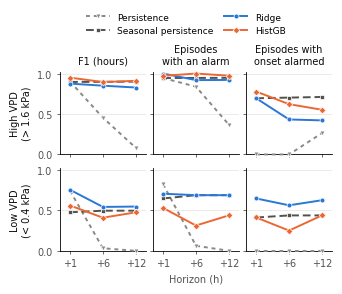

saved: paper\IEEE_Conference_Template\figures\vpd_events.pdf


In [17]:
# ---- 2b.11b — Figure for the paper: detection of critical-VPD events, all folds together ----
# Reads the table saved by 2b.11, so it can run on its own.
import os
import pandas as pd
import matplotlib.pyplot as plt

ev = pd.read_csv(os.path.join("paper", "tables", "rolling_origin_vpd_events.csv"))
FIG_METHODS = {  # label, color, line style, marker
    "persistence": ("Persistence", "#8a8983", (0, (2, 2)), "v"),
    "seasonal persistence": ("Seasonal persistence", "#52514e", (0, (4, 2)), "s"),
    "Ridge": ("Ridge", "#2a78d6", "-", "o"),
    "HistGB": ("HistGB", "#eb6834", "-", "D"),
}
FIG_METRICS = [("F1 (h)", "F1 (hours)"), ("episode recall", "Episodes\nwith an alarm"),
               ("onset hit rate", "Episodes with\nonset alarmed")]
FIG_EVENTS = [("high", "High VPD\n(> 1.6 kPa)"), ("low", "Low VPD\n(< 0.4 kPa)")]
hz = sorted(ev["horizon (h)"].unique())

plt.rcParams.update({"font.size": 7, "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6})
fig, axes = plt.subplots(2, 3, figsize=(3.5, 2.9), sharex=True, sharey=True)
for r, (kind, title) in enumerate(FIG_EVENTS):
    for c, (metric, lab) in enumerate(FIG_METRICS):
        ax = axes[r, c]
        for m, (name, col, ls, mk) in FIG_METHODS.items():
            s = ev[(ev.event == kind) & (ev.forecast == m)].set_index("horizon (h)")[metric].reindex(hz)
            ax.plot(range(len(hz)), s.values, color=col, ls=ls, lw=1.4, marker=mk, ms=3.5,
                    mec="white", mew=0.5, label=name, clip_on=False, zorder=3)
        ax.set_ylim(0, 1.02)
        ax.set_xticks(range(len(hz)), [f"+{h}" for h in hz])
        ax.set_xlim(-0.3, len(hz) - 0.7)
        ax.grid(axis="y", color="#e4e3df", lw=0.5, zorder=0)
        ax.spines[["top", "right"]].set_visible(False)
        ax.tick_params(length=2, colors="#52514e")
        if r == 0:
            ax.set_title(lab, fontsize=7, color="#0b0b0b")
    axes[r, 0].set_ylabel(title, fontsize=7, color="#0b0b0b")
h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc="upper center", ncol=2, frameon=False, fontsize=6.5, bbox_to_anchor=(0.55, 1.0),
           handlelength=2.6, columnspacing=1.2)
axes[1, 1].set_xlabel("Horizon (h)", fontsize=7, color="#52514e")
fig.tight_layout(rect=(0, 0, 1, 0.9), h_pad=0.6, w_pad=0.4)
out = os.path.join("paper", "IEEE_Conference_Template", "figures", "vpd_events.pdf")
fig.savefig(out, bbox_inches="tight")
plt.show()
print("saved:", out)

## 2b.12 — Computational cost of each model

Time needed by each model on fold 4 (the longest training period, so an upper bound for the other folds) with feature set 5:

* **selection (s)**: search on the validation period (grid for the tabular models, Bayesian optimization for the networks);
* **one final fit (s)**: one refit on the outer training period (the networks are refitted once per seed, so their final stage costs three times this);
* **protocol (s)**: selection + final stage, as in 2b.2;
* **one forecast (ms)**: latency of one hourly forecast (median of 20 calls), and the same per hour when the whole test window is predicted at once.

The cell prints the machine it ran on, which has to be reported with the times. It ends with an upper bound for the whole run of 2b.2. Each model is saved as soon as it is timed, so an interrupted run continues where it stopped (`TIME_RERUN = True` times everything again). The networks repeat their hyperparameter search, which takes most of the time.

In [18]:
# ---- 2b.12 — Computational cost of each model (fold 4, feature set 5) ----
# Needs 2b.1 (D, folds, BUDGET). For every model, the two-stage protocol of 2b.2 is run again on fold 4 and timed:
# selection (search on the validation period) + final stage (refit on the outer training period, one fit per seed for
# the networks). The final model is then refitted once more to time a single fit and the forecast latency.
# Fold 4 has the longest training period, so its times are an upper bound for the other folds.
# Results are saved after each model, so an interrupted run continues where it stopped.
import platform
import dataclasses

TIME_FOLD = folds[-1]
TIME_FS = FS_MAIN
TIME_PATH = os.path.join("paper", "tables", "rolling_origin_timing.csv")
TIME_RERUN = False          # True times every model again
N_LAT = 20                  # repetitions for the latency of one forecast (median reported)
TIME_BUDGET = dataclasses.replace(BUDGET, kt_dir="kt_tuning_timing")   # does not touch the tuner files of 2b.2


def machine_info():
    import os as _os
    info = {"platform": platform.platform(), "processor": platform.processor() or platform.machine(),
            "logical CPUs": _os.cpu_count()}
    try:
        import tensorflow as tf
        info["TensorFlow"] = tf.__version__
        info["GPU"] = ", ".join(d.name for d in tf.config.list_physical_devices("GPU")) or "none"
    except ImportError:
        info["TensorFlow"] = "not installed"
    return info


def is_hist(name):
    return not name.endswith("(t only)") and (name in fu.NEURAL_ARCHS or name.endswith("(hist)"))


def median_time(fn, n=N_LAT):
    fn()                                            # warm-up
    t = []
    for _ in range(n):
        t0 = time.perf_counter()
        fn()
        t.append(time.perf_counter() - t0)
    return float(np.median(t))


def time_model(runner, name, cols):
    arch = name.split(" ")[0]
    lookbacks = TIME_BUDGET.lookback_grid if is_hist(name) else (1,)
    t0 = time.perf_counter()
    if arch in fu.TABULAR:
        out = runner.run_tabular(arch, cols, lookbacks)
    else:
        out = runner.run_neural(arch, cols, lookbacks, label=f"timing_{name}_{TIME_FS}")
    t_protocol = time.perf_counter() - t0
    p, L = out["params"], out["params"]["lookback"]
    F = runner.prepare(cols, "final")
    if arch in fu.TABULAR:
        ctor = runner.search_space()[arch][0]
        Xtr, Xev = fu.flat(F["Xtr"], L), fu.flat(F["Xev"], L)
        t0 = time.perf_counter()
        m = ctor({k: v for k, v in p.items() if k != "lookback"}).fit(Xtr, F["ytr"])
        t_fit = time.perf_counter() - t0
        n_fits = 1
        one, batch = Xev[-1:], Xev
        predict = m.predict
    else:
        Xtr, Xev = fu.last(F["Xtr"], L), fu.last(F["Xev"], L)
        t0 = time.perf_counter()
        m = fu.NEURAL_BUILDERS[arch](n_features=F["Xtr"].shape[-1], n_targets=len(TARGET_COLS), lookback=L,
                                     units=p["units"], dropout=p["dropout"], lr=p["lr"], optimizer=p["optimizer"],
                                     seed=TIME_BUDGET.seeds[0])
        m.fit(Xtr, F["ytr"], epochs=p["epochs"], batch_size=32, verbose=0)
        t_fit = time.perf_counter() - t0
        n_fits = len(TIME_BUDGET.seeds)
        one, batch = Xev[-1:], Xev
        predict = lambda X: m.predict(X, verbose=0)
    t_one = median_time(lambda: predict(one))
    t_batch = median_time(lambda: predict(batch), n=5)
    return {"model": name, "family": "tabular" if arch in fu.TABULAR else "neural",
            "protocol (s)": t_protocol, "final fits": n_fits, "one final fit (s)": t_fit,
            "selection (s)": max(t_protocol - n_fits * t_fit, 0.0),
            "one forecast (ms)": 1e3 * t_one, "test window, per hour (ms)": 1e3 * t_batch / len(batch),
            "n train hours": len(Xtr), "n test hours": len(batch), "params": str(p)}


print("Machine:", machine_info())
done = pd.read_csv(TIME_PATH) if (os.path.exists(TIME_PATH) and not TIME_RERUN) else pd.DataFrame()
rows = done.to_dict("records")
todo = [m for m in fu.MODEL_ORDER if done.empty or m not in set(done["model"])]
if todo:
    time_runner = fu.FoldRunner(D, TIME_FOLD, TIME_BUDGET)
    time_cols = D["feature_sets"][TIME_FS]
    for name in todo:
        r = time_model(time_runner, name, time_cols)
        rows.append(r)
        pd.DataFrame(rows).to_csv(TIME_PATH, index=False)
        print(f"{name:>20} | protocol {r['protocol (s)']:7.1f} s | one fit {r['one final fit (s)']:6.2f} s | "
              f"one forecast {r['one forecast (ms)']:6.1f} ms")

TIMING = pd.DataFrame(rows).set_index("model").reindex(fu.MODEL_ORDER)
show = ["family", "selection (s)", "one final fit (s)", "protocol (s)", "one forecast (ms)", "test window, per hour (ms)"]
print(f"\nCost per model on {TIME_FOLD.name} ({int(TIMING['n train hours'].iloc[0])} training hours, "
      f"{int(TIMING['n test hours'].iloc[0])} test hours), feature set '{TIME_FS}':")
display(TIMING[show].round(3))

print("Mean by family:")
display(TIMING.groupby("family")[show[1:]].mean().round(3))

# upper bound for the whole rolling-origin run of 2b.2 (every fold is at most as long as fold 4)
total_h = TIMING["protocol (s)"].sum() * len(RO_FEATURE_SETS) * len(folds) / 3600
print(f"Upper bound for 2b.2 ({len(folds)} folds x {len(RO_FEATURE_SETS)} feature sets x {len(TIMING)} models): "
      f"{total_h:.1f} h, of which tabular "
      f"{TIMING.loc[TIMING.family == 'tabular', 'protocol (s)'].sum() * len(RO_FEATURE_SETS) * len(folds) / 3600:.2f} h")
print("saved:", TIME_PATH)

Machine: {'platform': 'Windows-10-10.0.19045-SP0', 'processor': 'AMD64 Family 23 Model 113 Stepping 0, AuthenticAMD', 'logical CPUs': 16, 'TensorFlow': '2.21.0', 'GPU': 'none'}
               Ridge | protocol     0.1 s | one fit   0.00 s | one forecast    0.2 ms
        RandomForest | protocol     1.8 s | one fit   0.47 s | one forecast   40.1 ms
              HistGB | protocol    19.8 s | one fit   4.69 s | one forecast   18.2 ms

       LSTM (t only) | protocol    77.0 s | one fit   4.97 s | one forecast   50.8 ms
        GRU (t only) | protocol    58.3 s | one fit   2.17 s | one forecast   55.0 ms


c:\Users\psyey\OneDrive\Escritorio\Git_repos\venvOsirisWater\Lib\site-packages\keras\src\ops\nn.py:947: UserWarning: You are using a softmax over axis 3 of a tensor of shape (None, 4, 1, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(
c:\Users\psyey\OneDrive\Escritorio\Git_repos\venvOsirisWater\Lib\site-packages\keras\src\ops\nn.py:947: UserWarning: You are using a softmax over axis 3 of a tensor of shape (32, 4, 1, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(
c:\Users\psyey\OneDrive\Escritorio\Git_repos\venvOsirisWater\Lib\site-packages\keras\src\ops\nn.py:947: UserWarning: You are using a softmax over axis 3 of a tensor of shape (None, 4, 1, 1). This axis has size 1. The softmax operation will always return the value 1, which is li

  Attention (t only) | protocol    88.1 s | one fit   3.58 s | one forecast   56.4 ms
        MLP (t only) | protocol    61.9 s | one fit   2.48 s | one forecast   51.9 ms


c:\Users\psyey\OneDrive\Escritorio\Git_repos\venvOsirisWater\Lib\site-packages\sklearn\linear_model\_ridge.py:265: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 3.046014995788937e-08.
  dual_coef = linalg.solve(K, y, assume_a="pos", overwrite_a=False)
c:\Users\psyey\OneDrive\Escritorio\Git_repos\venvOsirisWater\Lib\site-packages\sklearn\linear_model\_ridge.py:265: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 5.441778938575226e-08.
  dual_coef = linalg.solve(K, y, assume_a="pos", overwrite_a=False)


        Ridge (hist) | protocol     0.8 s | one fit   0.01 s | one forecast    0.2 ms
 RandomForest (hist) | protocol    37.6 s | one fit   1.26 s | one forecast   39.5 ms
       HistGB (hist) | protocol   948.0 s | one fit  76.48 s | one forecast   19.6 ms
                LSTM | protocol    82.0 s | one fit   2.41 s | one forecast   51.8 ms
                 GRU | protocol   109.8 s | one fit   2.19 s | one forecast   52.7 ms
           Attention | protocol    98.8 s | one fit   2.98 s | one forecast   52.9 ms
                 MLP | protocol    67.4 s | one fit   2.08 s | one forecast   52.0 ms

Cost per model on fold 4 (1070 training hours, 292 test hours), feature set '+ day-ahead forecast':


,family,selection (s),one final fit (s),protocol (s),one forecast (ms),"test window, per hour (ms)"
model,,,,,,
Ridge,tabular,0.112,0.002,0.115,0.152,0.001
RandomForest,tabular,1.375,0.469,1.844,40.073,0.173
HistGB,tabular,15.057,4.694,19.752,18.184,0.108
LSTM (t only),neural,62.112,4.970,77.023,50.811,0.224
GRU (t only),neural,51.782,2.168,58.285,55.025,0.234
Attention (t only),neural,77.310,3.581,88.053,56.432,0.242
MLP (t only),neural,54.465,2.484,61.916,51.885,0.206
Ridge (hist),tabular,0.801,0.006,0.807,0.158,0.001
RandomForest (hist),tabular,36.351,1.261,37.612,39.547,0.169


Mean by family:


,selection (s),one final fit (s),protocol (s),one forecast (ms),"test window, per hour (ms)"
family,,,,,
neural,71.821,2.859,80.398,52.950,0.231
tabular,154.203,13.818,168.021,19.623,0.101


Upper bound for 2b.2 (4 folds x 2 feature sets x 14 models): 3.7 h, of which tabular 2.24 h
saved: paper\tables\rolling_origin_timing.csv


In [19]:
# ---- 2b.12b — Size of each model (fold 4, feature set 5), next to its cost ----
# Needs 2b.1 (D, folds) and 2b.12 (TIME_FOLD, TIME_FS, TIME_BUDGET, TIME_PATH). Uses the hyperparameters selected in
# 2b.12, so sizes and times refer to the same models. Size = trainable weights for Ridge and the networks (counted
# without training), tree nodes for RF and HistGB (the final model is refitted once to count them).
import ast

SIZE_PATH = os.path.join("paper", "tables", "rolling_origin_model_size.csv")
TIMING = pd.read_csv(TIME_PATH).set_index("model").reindex(fu.MODEL_ORDER)
size_runner = fu.FoldRunner(D, TIME_FOLD, TIME_BUDGET)
size_cols = D["feature_sets"][TIME_FS]
F_size = size_runner.prepare(size_cols, "final")
n_feat, n_out = F_size["Xtr"].shape[-1], len(TARGET_COLS)


def model_size(name, p):
    arch, L = name.split(" ")[0], int(p["lookback"])
    row = {"L": L, "inputs": n_feat * L}
    if arch == "Ridge":
        row.update(size=(n_feat * L + 1) * n_out, unit="weights", trees=0)
    elif arch in fu.TABULAR:
        ctor = size_runner.search_space()[arch][0]
        m = ctor({k: v for k, v in p.items() if k != "lookback"}).fit(fu.flat(F_size["Xtr"], L), F_size["ytr"])
        if arch == "RandomForest":
            row.update(size=sum(e.tree_.node_count for e in m.estimators_), unit="nodes", trees=len(m.estimators_))
        else:   # MultiOutputRegressor: one HistGradientBoostingRegressor per target
            trees = [t for e in m.estimators_ for it in e._predictors for t in it]
            row.update(size=sum(len(t.nodes) for t in trees), unit="nodes", trees=len(trees))
    else:
        net = fu.NEURAL_BUILDERS[arch](n_features=n_feat, n_targets=n_out, lookback=L, units=p["units"],
                                       dropout=p["dropout"], lr=p["lr"], optimizer=p["optimizer"], seed=0)
        row.update(size=int(net.count_params()), unit="weights", trees=0)
    return row


SIZE = pd.DataFrame({m: model_size(m, ast.literal_eval(TIMING.loc[m, "params"])) for m in fu.MODEL_ORDER}).T
SIZE["train hours"] = int(TIMING["n train hours"].iloc[0])
SIZE["size per train hour"] = SIZE["size"].astype(float) / SIZE["train hours"]
SIZE = SIZE.join(TIMING[["family", "protocol (s)", "one final fit (s)", "one forecast (ms)"]])
SIZE.index.name = "model"
SIZE.to_csv(SIZE_PATH)

print(f"Size and cost per model on {TIME_FOLD.name}, feature set '{TIME_FS}' ({n_feat} input variables, "
      f"{SIZE['train hours'].iloc[0]} training hours):")
display(SIZE[["family", "L", "inputs", "size", "unit", "trees", "size per train hour",
              "protocol (s)", "one final fit (s)", "one forecast (ms)"]]
        .astype({"size per train hour": float}).round(2))
print("saved:", SIZE_PATH)

Size and cost per model on fold 4, feature set '+ day-ahead forecast' (86 input variables, 1070 training hours):


,family,L,inputs,size,unit,trees,size per train hour,protocol (s),one final fit (s),one forecast (ms)
model,,,,,,,,,,
Ridge,tabular,1,86,522,weights,0,0.49,0.11,0.00,0.15
RandomForest,tabular,1,86,269884,nodes,200,252.23,1.84,0.47,40.07
HistGB,tabular,1,86,109800,nodes,1800,102.62,19.75,4.69,18.18
LSTM (t only),neural,1,86,114406,weights,0,106.92,77.02,4.97,50.81
GRU (t only),neural,1,86,71014,weights,0,66.37,58.29,2.17,55.02
Attention (t only),neural,1,86,48950,weights,0,45.75,88.05,3.58,56.43
MLP (t only),neural,1,86,18246,weights,0,17.05,61.92,2.48,51.88
Ridge (hist),tabular,3,258,1554,weights,0,1.45,0.81,0.01,0.16
RandomForest (hist),tabular,3,258,269884,nodes,200,252.23,37.61,1.26,39.55


saved: paper\tables\rolling_origin_model_size.csv


In [20]:
# ---- 2b.13 — History length L selected on validation, per model and fold ----
# Needs 2b.2 (RO). The current-hour versions use L = 1, so only the history versions are listed.
HIST_MODELS = [m for m in fu.MODEL_ORDER
               if not m.endswith("(t only)") and (m in fu.NEURAL_ARCHS or m.endswith("(hist)"))]
L_SEL = pd.DataFrame({(fs, fn): {m: int(RO[fn]["params"][(m, fs)]["lookback"]) for m in HIST_MODELS}
                      for fs in RO_FEATURE_SETS for fn in FOLDS})
L_SEL.columns.names = ["feature set", "fold"]
L_SEL.index.name = "model"
L_SEL.to_csv(os.path.join("paper", "tables", "rolling_origin_selected_L.csv"))
print("History length L (h) selected on validation, per feature set and fold (grid: "
      f"{', '.join(str(l) for l in BUDGET.lookback_grid)} h):")
display(L_SEL)

print(f"How often each L was selected with '{FS_MAIN}' (models x folds):")
display(L_SEL[FS_MAIN].stack().value_counts().sort_index().rename("count").to_frame().T)
print("saved:", os.path.join("paper", "tables", "rolling_origin_selected_L.csv"))

History length L (h) selected on validation, per feature set and fold (grid: 3, 6, 12, 24 h):


feature set         + cluster                      + day-ahead forecast                     
fold                   fold 1 fold 2 fold 3 fold 4               fold 1 fold 2 fold 3 fold 4
model                                                                                       
Ridge (hist)                3      3      3     12                    3      3      3      3
RandomForest (hist)         6      3      3     12                    6      3      3      3
HistGB (hist)              12     12     24      6                    6      6     24     12
LSTM                       12      3      3      3                   12     12      3     24
GRU                         3      6      6      3                    3      6      3      3
Attention                   6      3      3      6                    6      3      3      3
MLP                         6      3      3      3                    3     24      3      6

How often each L was selected with '+ day-ahead forecast' (models x folds):


,3,6,12,24
count,16,6,3,3


saved: paper\tables\rolling_origin_selected_L.csv
